# $0$. Imports and Configs

In [1]:
# IMPORTS
# I. General Imports
import os, json, hashlib, copy
import gymnasium as gym
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F

# II. Expert Demonstrations
from stable_baselines3 import PPO
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.callbacks import EvalCallback

In [2]:
# CONFIG
# Note: I try to keep all seeds different
# I. Environment
ENV_ID = "InvertedDoublePendulum-v5"
ACTION_SPACE = gym.make(ENV_ID).action_space

# II. Expert Demonstrations
EXPERT_SEED = 42
EXPERT_TIMESTEPS = 2_000_000
EXPERT_PATH = "models/ppo_expert_idp_discrete"
N_ACTION_BINS = 15
EXPERT_EVAL_SEEDS = list(range(100_000, 100_100))
POLICY_EVAL_SEEDS = list(range(100_100, 100_200))
EXPERT_SUCCESS_THRESHOLD = 9000

WARMUP_STEPS_GRID = [0, 1, 2, 3, 4, 5, 6, 8]
WARMUP_SCALES = [0.1, 0.5]
WARMUP_GATE = 0.97

N_DEMO_EPISODES = 200
DEMO_SEEDS = list(range(200_000, 200_000 + 2 * N_DEMO_EPISODES))
DEMO_PATH = "data_discrete/expert_demos.npz"
DEMO_META_PATH = "data_discrete/expert_demos_meta.json"

SPLIT_SEED = 250_000
TRAIN_FRACTION, VAL_FRACTION, TEST_FRACTION = 0.7, 0.15, 0.15
SPLIT_PATH = "data_discrete/expert_demos_split.json"

NORM_EPS = 1e-8
NORM_RANGE_FRACTION = 0.1
NORM_CLIP = 10.0
NORM_PATH = "data_discrete/normalizer.npz"

LABEL_SIZES = [32, 128, 512, 2048, 8192]
LABEL_SEEDS = [0, 1, 2, 3, 4]
LABEL_SEED_BASE = 13
LABEL_PATH = "data_discrete/label_subsets.json"

BC_SEED = 275_000

# III. Dynamics Data
N_DYN_EPISODES = 200
DYN_SEEDS = list(range(300_000, 300_000 + 2 * N_DYN_EPISODES))
DYN_PATH = "data_discrete/dynamics.npz"
DYN_META_PATH = "data_discrete/dynamics_meta.json"

DIAG_EPOCHS = 20
DIAG_SEED = 21

# IV. Stage 1: Latent Model (the paper's settings)
N_CODEBOOKS = 2
N_LATENTS = 4
EMBED_DIM = 8
N_CODES = 16
LATENT_DIM = N_CODEBOOKS * N_LATENTS * EMBED_DIM
COMMITMENT = 0.05
EMA_DECAY = 0.99
BATCH_SIZE = 128
STAGE1_STEPS = 50_000
STAGE1_LR = 3e-4
STAGE1_SEED = 31
STAGE1_PATH = "data_discrete/stage1_{}.pt"
STAGE1_RETRAIN = False
MAX_L2_GAP = 0.10

# V. Stage 2: Latent BC
STAGE2_STEPS = 60_000
STAGE2_LR = 2e-4
STAGE2_SEED = 41
STAGE2_PATH = "data_discrete/stage2.pt"

# VI. Stage 3: Offline Decoding
STAGE3_STEPS = 10_000
STAGE3_LR = 3e-4
STAGE3_SEED = 51

# VI B. Decoding Without Labels
SELF_PLAY_STEPS = 512
SELF_PLAY_ROUNDS = 6
SELF_PLAY_SEED_BASE = 500_000

# VII. Online Fine-Tuning
ONLINE_LABEL_SIZE = 512
ONLINE_STEPS = 300_000
ONLINE_SEED_BASE = 1_000_000
ONLINE_SEED = 61

# $I$. Environment And Evaluation

This notebook attempts to apply the LAPO framework to the MuJoCo Double Pendulum environment.

Paper: https://arxiv.org/abs/2312.10812

There are 2 claims that by the end of this notebook we hope to see:

1. Offline Label Efficiency: Using "cheap" state-only expert demonstrations, LAPO should be able to generate "expensive" action labels.
2. Online Sample Efficiency: Using expert demonstrations to induce a prior, LAPO should follow behavior cloning and reach successful performance faster than PPO from scratch.

These will be evaluated at each step of the framework (each section).

Gymnasium description & docs: https://gymnasium.farama.org/environments/mujoco/inverted_double_pendulum/

Standard MuJoCo Environment MDP Formation:

- State Space: $s_t = (q_t, \dot{q_t}) \in\mathbb{R}^6$, $q=(x, \theta_1, \theta_2)$

- Observation Space: $o_t = \phi(s_t)\in\mathbb{R}^9$. $\phi{(s)}$ is invertible as it can be completely recovered by $o$.

- Action Space: $a_t\in[-1, 1]$

- Reward Function: $r_t = R(s_t,a_t) = $ 
$\underbrace{10 \cdot\mathbf{1}_{\text{[Not Terminated]}}}_{\text{alive reward}}$ - 
$\underbrace{(0.01x^2_{tip} + (y_{tip} - 2)^2)}_{\text{distance penalty}}$ - 
$\underbrace{(10^{-3}\dot{\theta}^2_1 + 5 \times 10^{-3}\dot{\theta}^2_2)}_{\text{velocity penalty}}$

- Starting State: $s_0$ $\sim\rho_0^{(c)}$. Position $\sim\mathcal{U}_{[-c, c]^3}$, Velocity $\sim\mathcal{N}(0_3, c^2 I_3)$. c = reset_noise_scale which we can change to create harder starts.

- Truncation: Limits an episode at 1000 steps

- Termination: When the pendulum becomes "unhealthy" defined as: $y_{tip}\leq1$

- Dynamics: State transitions are deterministic, i.e. $s_{t+1} = f(s_t, a_t)$, $\Delta t = 0.05s$

- Discount: Not in MuJoCo environment, explicitly added in model later

In [3]:
# Simple Example of Random agent
env = gym.make(ENV_ID)
returns = []
for i in range(1000):
    observation, info = env.reset(seed=42 + i)
    total_reward, done = 0.0, False
    while not done:
        observation, reward, terminated, truncated, info = env.step(env.action_space.sample())
        total_reward += reward
        done = terminated or truncated
    returns.append(total_reward)
env.close()
print("Average Return On Random Policy: ", round(np.mean(returns), 4))

Average Return On Random Policy:  48.0532


# $II$. Expert And Demonstrations

The expert we will use is stable baselines 3's PPO model trained for up to 2 million steps. It serves as the main agent to compare LAPO to and generates all the demonstrations that LAPO will be built on. As such, it must perform at an expert level or else we can not assume that LAPO will be any good either.

Stable Baselines 3 docs: https://stable-baselines3.readthedocs.io/en/master/modules/ppo.html

Beyond simply ensuring that it reaches the 1000 step maximum, we also will test that it can perform well with different starts (to test a bit more on general skill), and that it can survive perturbations mid-episode as otherwise LAPO will also fail in later warm-ups.

Some more math notation:

Return $G_e = \sum_{t=0}^{T_e-1}r_t$, where $T_e =$ number of steps in episode $e$. 

$T_e \in \{1, ..., 1000\}$ where the upper limit is the step truncation threshold. 

The best possible score in theory is then $1000 \times \max{r_t} = 1000 \times 10 = 10000$, but we usually consider standard success as averaging over 9000.

Then, an agent's success rate is $\hat{p} = \frac{\# successes}{N_e} = \frac{1}{N_e}\sum_{e=1}^{N_e}\mathbf{1}_{\{T_e=1000\}}$ with standard error $\sqrt{\frac{\hat{p}(1-\hat{p})}{N_e}}$. $N_e$ is the number of episodes we evaluate the expert on.

We want our expert to reach truncation (1000 steps) on 97/100 tests to consider the baseline success. If it does not, we keep testing out different agent configurations until we reach a successful agent. This expert agent is not the purpose of this notebook and LAPO will not perform well if the underlying expert does not so this must pass before moving on.

An extra important note: Originally, the agent used the standard continuous action space, however what was found was that actions became so small that they were smaller than the model's error itself, causing the actions to be impossible to interpret or detect. The fix was to discretize the action space (torques) into N action bins which I chose to be 15. This dramatically improved the ability to detect actions which is vital to stage 1 of the model.


In [4]:
TORQUES = np.linspace(ACTION_SPACE.low[0], ACTION_SPACE.high[0], N_ACTION_BINS)

class DiscreteTorque(gym.ActionWrapper):
    """The expert picks one of N_ACTION_BINS evenly spaced torques."""
    def __init__(self, env):
        super().__init__(env)
        self.action_space = gym.spaces.Discrete(N_ACTION_BINS)
    def action(self, action):
        return np.array([TORQUES[int(action)]])

def make_discrete_env():
    return DiscreteTorque(gym.make(ENV_ID))

# Train the expert on vectorized environments, or load it if it is already saved
if not os.path.exists(f"{EXPERT_PATH}/best_model.zip"):
    vec_env = make_vec_env(make_discrete_env, n_envs=4, seed=EXPERT_SEED)
    eval_env = make_vec_env(make_discrete_env, n_envs=1, seed=EXPERT_SEED + 1_000)
    callback = EvalCallback(eval_env, best_model_save_path=EXPERT_PATH, eval_freq=25_000 // 4, n_eval_episodes=10, deterministic=True, verbose=0)
    PPO("MlpPolicy", vec_env, seed=EXPERT_SEED, verbose=0).learn(total_timesteps=EXPERT_TIMESTEPS, callback=callback)
    vec_env.close()
    eval_env.close()
expert = PPO.load(f"{EXPERT_PATH}/best_model")

def file_hash(path):
    with open(path, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()

EXPERT_SHA256 = file_hash(f"{EXPERT_PATH}/best_model.zip")

def expert_torques(obs_batch):
    """The expert's torques for a batch of observations, shape (N, 1)."""
    return TORQUES[expert.predict(obs_batch, deterministic=True)[0]].reshape(-1, 1)

# Quick check that expert is able to reach standard success by scoring 9000
env = make_discrete_env()
returns, lengths = [], []
for seed in EXPERT_EVAL_SEEDS:
    obs, info = env.reset(seed=seed)
    episode_return, steps, done = 0.0, 0, False
    while not done:
        obs, reward, terminated, truncated, info = env.step(expert.predict(obs, deterministic=True)[0])
        episode_return, steps, done = episode_return + reward, steps + 1, terminated or truncated
    returns.append(episode_return)
    lengths.append(steps)
env.close()
print(f"Return over {len(returns)} episodes: {np.mean(returns):.1f} +/- {np.std(returns):.1f}")
print(f"Episodes reaching the 1000-step limit: {sum(n == 1000 for n in lengths)}/{len(lengths)}")

Return over 100 episodes: 9355.7 +/- 0.4
Episodes reaching the 1000-step limit: 100/100


The next part of our evaluation is warm-ups. Let's define it first:

A warm up modifier $W^{(k)}_e(w)$ means that episode $e$ has the first $k$ steps as random actions selected uniformly at random in $[-w,w]$. The expert then takes control of the rest of the episode. Later on we do not save the warm-ups, only the expert demonstrations. We extend the harness function to include this feature.

In [5]:
# Harness Function
def harness_function(policy, policy_name, seed_list, c, k=0, w=0.0):
    """One episode of policy (obs -> action) per seed, with reset noise c and the first k steps replaced by random shoves
    in [-w, w]. Returns one row per episode."""
    rows = []
    env = gym.make(ENV_ID, reset_noise_scale=c)
    for seed in seed_list:
        obs, info = env.reset(seed=seed)
        rng = np.random.default_rng([seed, 1])
        episode_return, steps, done, min_height = 0.0, 0, False, env.unwrapped.data.site_xpos[0][2]
        while not done:
            action = policy(obs) if steps >= k else rng.uniform(-w, w, size=ACTION_SPACE.shape)
            obs, reward, terminated, truncated, info = env.step(action)
            episode_return, steps, done = episode_return + reward, steps + 1, terminated or truncated
            min_height = min(env.unwrapped.data.site_xpos[0][2], min_height)
        rows.append({"Policy": policy_name, "c": c, "Return": episode_return, "Length": steps, "Success": int(truncated and not terminated),
                     "Min_height": min_height, "Seed": seed, "Warmup_steps": k, "Warmup_scale": w, "Fell_in_warmup": int(terminated and steps <= k)})
    env.close()
    return pd.DataFrame(rows)

# Summary Function
def summarize_group(group):
    """All summary statistics for one (Policy, c) group."""
    n, p_hat = len(group), group["Success"].mean()
    successful = group[group["Success"] == 1]
    return pd.Series({
        "N": n,
        "Success_rate": p_hat,
        "Success_se": np.sqrt(p_hat * (1 - p_hat) / n),
        # Exact 95% upper bound on the failure rate, only meaningful with zero failures
        "Failure_bound_95": 1 - 0.05 ** (1 / n) if group["Success"].all() else np.nan,
        "Return_mean": group["Return"].mean(),
        "Return_std": group["Return"].std(),
        # Successful episodes only, NaN if there are none
        "Return_per_step": (successful["Return"] / successful["Length"]).mean(),
        "Length_mean": group["Length"].mean(),
        "Min_height_mean": group["Min_height"].mean(),
        "Min_height_min": group["Min_height"].min(),
    })

def summary_function(df, by=["Policy", "c"]):
    return df.groupby(by).apply(summarize_group, include_groups=False).reset_index().astype({"N": int})

# Policies
expert_policy = lambda obs: expert_torques(obs[None])[0]
zero_policy = lambda obs: np.zeros(ACTION_SPACE.shape)
random_policy = lambda obs: np.random.uniform(ACTION_SPACE.low, ACTION_SPACE.high, size=ACTION_SPACE.shape)

# Plotting: one fixed colour per policy, and one shared style for every figure
POLICY_COLORS = {"Expert": "#2a78d6", "Direct BC": "#eb6834", "LAPO": "#1baf7a"}
EXTRA_COLORS = ["#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
DEFAULT_XLABELS = {"c": "Reset noise scale $c$", "Warmup_steps": "Warm-up steps $k$"}

def style_axes(ax):
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(MUTED)
    ax.tick_params(colors=MUTED)

def plot_survival(summary, x="c", hue="Policy", hue_format="{}", ax=None, reference=None, reference_label=None, title=None, xlabel=None):
    """Success rate against x (a column of summary_function's output), one line per value of hue, optional dashed line at x = reference."""
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 4.2))
    extra = iter(EXTRA_COLORS)
    levels = list(dict.fromkeys(summary[hue]))
    for level in levels:
        group = summary[summary[hue] == level].sort_values(x)
        label = hue_format.format(level)
        p, se, bound = (group[col].to_numpy(dtype=float) for col in ["Success_rate", "Success_se", "Failure_bound_95"])
        # Where the success rate is 1 its standard error is 0, so the zero-failure 95% bound is shown as the lower bar instead
        lower, upper = np.where(np.isfinite(bound), bound, np.minimum(se, p)), np.minimum(se, 1 - p)
        ax.errorbar(group[x], p, yerr=[lower, upper], label=label, color=POLICY_COLORS.get(label) or next(extra), linewidth=2, marker="o",
                    markersize=7, markeredgecolor="white", markeredgewidth=1.5, elinewidth=1.2, capsize=3, zorder=3)
    if reference is not None:
        ax.axvline(reference, color=MUTED, linestyle="--", linewidth=1, zorder=1)
        if reference_label:
            ax.annotate(reference_label, (reference, 0.04), xytext=(5, 0), textcoords="offset points", color=MUTED, fontsize=9)
    n_values = sorted(set(summary["N"]))
    n_text = f"N = {n_values[0]}" if len(n_values) == 1 else f"N = {n_values[0]}–{n_values[-1]}"
    ax.set_xticks(sorted(summary[x].unique()))
    ax.set_ylim(-0.02, 1.05)
    ax.set_ylabel("Success rate", color=INK)
    ax.set_xlabel(xlabel or DEFAULT_XLABELS.get(x, x), color=INK)
    ax.set_title(title or f"Survival under perturbation ({n_text} episodes per point)", color=INK, fontsize=11, loc="left")
    style_axes(ax)
    if len(levels) > 1:
        ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1.0))
    return ax

The next thing to do is to test the three policies (expert, zero, random), check that the expert passes the gate, and find the largest warm-up the expert reliably survives.

Policy,c,N,Success_rate,Success_se,Failure_bound_95,Return_mean,Return_std,Return_per_step,Length_mean,Min_height_mean,Min_height_min
Expert,0.100,100,1.000,0.000,0.030,9355.720,0.304,9.356,1000.000,1.192,1.164
Random,0.100,100,0.000,0.000,nan,44.860,15.962,nan,6.040,0.926,0.756
Zero,0.100,100,0.000,0.000,nan,86.173,16.331,nan,10.450,0.946,0.885


Largest safe k per w: {0.1: 1, 0.5: 0}  ->  MAX_WARMUP_STEPS = 1, WARMUP_SCALE = 0.1


<Axes: title={'left': 'Expert success after surviving the warm-up'}, xlabel='Warm-up steps $k$', ylabel='Success rate'>

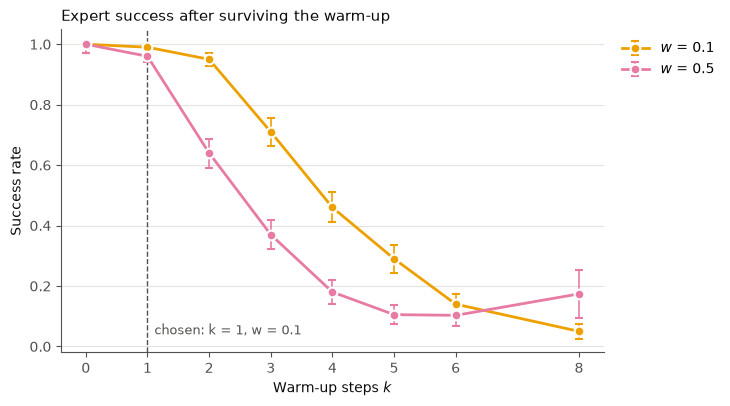

In [6]:
c = 0.1
results = pd.concat([harness_function(policy, name, POLICY_EVAL_SEEDS, c)
                     for name, policy in [("Expert", expert_policy), ("Zero", zero_policy), ("Random", random_policy)]], ignore_index=True)
statistics = summary_function(results)
display(statistics.style.format(precision=3).hide(axis="index"))

# GATE
expert_stats = statistics[(statistics["Policy"] == "Expert") & (statistics["c"] == 0.1)]
assert expert_stats["Return_mean"].item() >= EXPERT_SUCCESS_THRESHOLD, "Expert did not reach the return threshold."
assert expert_stats["Success_rate"].item() >= 0.97, "Expert did not have a high success rate."

# Warm-ups: the expert's success after k random shoves of size up to w
results_b_grid = pd.concat([harness_function(expert_policy, "Expert", POLICY_EVAL_SEEDS, c, k, w)
                            for w in WARMUP_SCALES for k in WARMUP_STEPS_GRID], ignore_index=True)
summary_b = summary_function(results_b_grid[results_b_grid["Fell_in_warmup"] == 0], by=["Policy", "Warmup_scale", "Warmup_steps"])

# k = 0 never uses the warm-up, so it must reproduce the gate run exactly
assert (summary_b.loc[summary_b["Warmup_steps"] == 0, "Success_rate"] == expert_stats["Success_rate"].item()).all(), "k = 0 does not match the gate run."

# Largest k per w such that every k' <= k passes the gate, then the largest k overall (the larger w on ties)
max_safe_k = {}
for w in WARMUP_SCALES:
    group = summary_b[summary_b["Warmup_scale"] == w].sort_values("Warmup_steps")
    max_safe_k[w] = int(group.loc[(group["Success_rate"] >= WARMUP_GATE).cummin(), "Warmup_steps"].max())
MAX_WARMUP_STEPS = max(max_safe_k.values())
WARMUP_SCALE = max(w for w, k in max_safe_k.items() if k == MAX_WARMUP_STEPS)
print(f"Largest safe k per w: {max_safe_k}  ->  MAX_WARMUP_STEPS = {MAX_WARMUP_STEPS}, WARMUP_SCALE = {WARMUP_SCALE}")

plot_survival(summary_b, x="Warmup_steps", hue="Warmup_scale", hue_format="$w$ = {}", reference=MAX_WARMUP_STEPS,
              reference_label=f"chosen: k = {MAX_WARMUP_STEPS}, w = {WARMUP_SCALE}", title="Expert success after surviving the warm-up")

Now that we've confirmed that the expert works, we can gather demonstrations. The LAPO agent can not perform better than the demonstrations themselves, so it is vital to take demonstrations carefully. Let's start with the math:

Expert Trajectory: The path taken by the expert in an episode $\tau_e = (o_{k_e}, a_{k_e}, o_{k_e+1}, ..., o_{T_e-1}, a_{T_e-1}, o_{T_e})$ where the trajectory only starts after the warm-up. Each trajectory is a function of the seed and warmup attributed to $e$.

Expert Dataset: We collect transitions to form a supervised dataset $\mathcal{D}_E = \{(o_t, a_t, o_{t+1}): t\geq k_e\}$. Note that this is a privileged dataset and we will only collect this for comparison. In reality, we will only ever use the state-only transition dataset $\mathcal{D}_E = \{(o_t, o_{t+1}): t\geq k_e\}$ which is the main purpose of LAPO to utilize this.

Occupancy: After the agent reaches a upright position (usually in around 200 steps based on later results), it can usually stay in that same state thus achieving a steady state for the next 800 or so steps until truncation. This means that the expert dataset will be 80% the same state which affects the training loss severely.

Define the distribution of states from the expert dataset as $p_E$, and all the models will attempt to minimize $\mathcal{L}(\theta) = \frac{1}{\# Rows}\sum_{rows}{\mathcal{l}_\theta (s_i)} = E_{s\sim p_E}[\mathcal{l}_\theta(s)]$ which is the average loss over our rows. Therefore $p_E$ will determine what the model is graded on. That explains how occupancy affects the model's training and whether that will be good or not. If it trains mostly over steady state, it won't know how to act in the non-steady states which are the more important states.

Let the probability of picking a state from a row be $p_E(s) = \frac{1}{\# Rows}\sum_{e}\sum_{t}\mathbf{1}_{\{s_t=s\}}$ which is the proportion of rows over all steps and episodes that we are in state $s$. If we include warmups, we get by the law of total probability that $p_E = \sum_{k}\mathbb{P}(k_e=k)p_E^{(k)}$. Since it takes longer for the agent to reach steady state when it starts from a pushed warmup, we therefore can shift a bit of the dataset to transient states from a dominated steady state dataset. That's one of the main reasons we use warmups!

That is the general math for demonstrations and what we will be collecting for our LAPO agent to get its prior from. 

In [7]:
# Collector function
def collect_demonstrations(policy, seed_list, n_episodes, c, max_warmup_steps, w):
    """Successful episodes only: keep trying seeds until n_episodes are saved. The k warm-up steps are not recorded."""
    env = gym.make(ENV_ID, reset_noise_scale=c)
    demonstrations, seeds = [], []
    for seed in seed_list:
        obs, info = env.reset(seed=seed)
        rng = np.random.default_rng([seed, 1])
        k = np.random.default_rng([seed, 2]).integers(0, max_warmup_steps, endpoint=True)
        transitions, steps, done = [], 0, False
        while not done:
            action = policy(obs) if steps >= k else rng.uniform(-w, w, size=ACTION_SPACE.shape)
            qpos, qvel = env.unwrapped.data.qpos.copy(), env.unwrapped.data.qvel.copy()
            next_obs, reward, terminated, truncated, info = env.step(action)
            if steps >= k:
                transitions.append((obs, action, next_obs, reward, terminated, truncated, qpos, qvel, steps, k))
            obs, steps, done = next_obs, steps + 1, terminated or truncated
        if truncated and not terminated:
            demonstrations.append(transitions)
            seeds.append(seed)
        if len(demonstrations) == n_episodes:
            break
    env.close()
    assert len(demonstrations) == n_episodes, f"{n_episodes} were not recovered before exhausting the entire list of {len(seed_list)} seeds."
    return {"Demonstration": demonstrations, "Seed": seeds}

FIELDS = ["obs", "action", "next_obs", "reward", "terminated", "truncated", "qpos", "qvel", "t", "warmup_steps"]

def flatten_episodes(episodes, kept_seeds):
    """Episodes (lists of transition tuples) -> one array per field with the rows stacked in order, plus each row's episode and seed."""
    data = {name: np.array([tr[i] for ep in episodes for tr in ep]) for i, name in enumerate(FIELDS)}
    lengths = [len(ep) for ep in episodes]
    data["episode_id"] = np.repeat(np.arange(len(episodes)), lengths)
    data["seed"] = np.repeat(kept_seeds, lengths)
    return data

def check_dataset(data, meta, keeps_failures):
    """Bookkeeping for every episode, its first observation regenerated from its seed, and a physics replay of every row
    (restore the saved state, apply the saved action, compare with the saved result). Returns the largest next_obs error."""
    env = gym.make(ENV_ID, reset_noise_scale=meta["reset_noise_scale"])
    for e in range(meta["n_episodes"]):
        rows = np.flatnonzero(data["episode_id"] == e)
        k, seed = data["warmup_steps"][rows[0]], int(data["seed"][rows[0]])
        done = data["terminated"][rows] | data["truncated"][rows]
        assert len(rows) <= 1000 - k and done[-1] and not done[:-1].any(), f"Episode {e}: does not end exactly on its last row."
        assert keeps_failures or not data["terminated"][rows].any(), f"Episode {e}: a kept episode terminated."
        assert data["t"][rows[0]] == k and np.all(np.diff(data["t"][rows]) == 1), f"Episode {e}: steps do not start after the warm-up or skip."
        assert np.array_equal(data["obs"][rows][1:], data["next_obs"][rows][:-1]), f"Episode {e}: obs and next_obs are misaligned."
        obs, info = env.reset(seed=seed)
        rng = np.random.default_rng([seed, 1])
        for step in range(k):
            obs, *_ = env.step(rng.uniform(-meta["warmup_scale"], meta["warmup_scale"], size=ACTION_SPACE.shape))
        assert np.array_equal(obs, data["obs"][rows[0]]), f"Episode {e}: could not regenerate its first observation from seed {seed}."
    env.close()

    assert np.isin(data["action"], TORQUES).all(), "An action is not one of the torques."
    env = gym.make(ENV_ID)
    env.reset(seed=0)
    replay_error, reward_error = 0.0, 0.0
    for i in range(len(data["obs"])):
        env.unwrapped.set_state(data["qpos"][i], data["qvel"][i])
        obs, reward, terminated, *_ = env.unwrapped.step(data["action"][i])
        replay_error = max(replay_error, np.abs(obs - data["next_obs"][i]).max())
        reward_error = max(reward_error, abs(reward - data["reward"][i]))
        assert terminated == data["terminated"][i], f"Row {i}: replay does not reproduce the terminated flag."
    env.close()
    assert replay_error < 1e-10 and reward_error < 1e-10, f"Replay does not reproduce the data (errors {replay_error:.2e}, {reward_error:.2e})."
    return replay_error

In [8]:
# Demo seeds must never be evaluation seeds
assert not set(DEMO_SEEDS) & (set(POLICY_EVAL_SEEDS) | set(EXPERT_EVAL_SEEDS)), "Demo seeds overlap evaluation seeds."
out = collect_demonstrations(expert_policy, DEMO_SEEDS, N_DEMO_EPISODES, c, MAX_WARMUP_STEPS, WARMUP_SCALE)
episodes, kept_seeds = out["Demonstration"], out["Seed"]
demos = flatten_episodes(episodes, kept_seeds)
N = len(demos["obs"])
assert all(len(values) == N for values in demos.values()), "The fields have different numbers of rows."
assert demos["obs"].shape == (N, 9) and demos["next_obs"].shape == (N, 9) and demos["action"].shape == (N, 1), "Observation or action shape is wrong."
assert demos["qpos"].shape == (N, 3) and demos["qvel"].shape == (N, 3), "MuJoCo state shape is wrong."

# Save the arrays and a small readable file recording how this dataset was made
os.makedirs(os.path.dirname(DEMO_PATH), exist_ok=True)
np.savez_compressed(DEMO_PATH, **demos)
n_seeds_tried = DEMO_SEEDS.index(kept_seeds[-1]) + 1
metadata = {"env_id": ENV_ID, "expert_path": EXPERT_PATH, "expert_sha256": EXPERT_SHA256, "reset_noise_scale": float(c),
            "max_warmup_steps": int(MAX_WARMUP_STEPS), "warmup_scale": float(WARMUP_SCALE), "n_episodes": len(episodes), "n_transitions": int(N),
            "n_seeds_tried": n_seeds_tried, "n_discarded": n_seeds_tried - len(episodes), "kept_seeds": [int(s) for s in kept_seeds],
            "fields": list(demos.keys())}
with open(DEMO_META_PATH, "w") as f:
    json.dump(metadata, f, indent=2)

# Load back, confirm the file matches what is in memory, and check it; every later cell works from the loaded copy
with np.load(DEMO_PATH) as f:
    loaded = dict(f)
assert loaded.keys() == demos.keys() and all(np.array_equal(loaded[name], demos[name]) for name in demos), "Saved file does not match memory."
demos = loaded
with open(DEMO_META_PATH) as f:
    max_replay_error = check_dataset(demos, json.load(f), keeps_failures=False)

# The saved actions are the expert's deterministic actions (batched predict rounds slightly differently)
label_mismatch = np.mean(np.abs(expert_torques(demos["obs"]) - demos["action"]) > 1e-9)
assert label_mismatch < 1e-4, f"Saved actions are not the expert's ({label_mismatch:.2%} of rows differ)."
print(f"{metadata['n_episodes']} episodes, {N} transitions ({metadata['n_discarded']} discarded). Checks passed: bookkeeping, "
      f"first observations regenerated, replay error {max_replay_error:.1e}, labels differing from the expert {label_mismatch:.3%}")

200 episodes, 199896 transitions (1 discarded). Checks passed: bookkeeping, first observations regenerated, replay error 0.0e+00, labels differing from the expert 0.001%


A few details worth mentioning for completion:

For training/validation/testing, we split our dataset by episode, not by individual transitions. Transitions are not independent but episodes (trajectories) are since they are built off their own individual seed.

The training set will be used for statistics and normalization, the validation set will be used for model selection, and the testing set will be our evaluation.

Normalization is important as the features all run at their own scales. Additionally, we can drop any feature that doesn't vary (standard deviation = 0) as they will not help the model in any way.

In [9]:
# Split
def train_val_test_split(demos, train_percent=0.7, val_percent=0.2, test_percent=0.1):
    """Split by episode, shuffled with SPLIT_SEED; returns the three splits and which episodes went where."""
    assert np.isclose(train_percent + val_percent + test_percent, 1)
    n = demos["episode_id"].max() + 1
    order = np.random.default_rng(SPLIT_SEED).permutation(n)
    n_train, n_val = int(round(n * train_percent)), int(round(n * val_percent))
    ids = {"train": order[:n_train], "val": order[n_train:n_train + n_val], "test": order[n_train + n_val:]}
    masks = {part: np.isin(demos["episode_id"], episode_ids) for part, episode_ids in ids.items()}
    assert np.all(sum(mask.astype(int) for mask in masks.values()) == 1), "A row is in zero or several splits."
    splits = [{name: values[masks[part]] for name, values in demos.items()} for part in ids]
    return (*splits, {part: episode_ids.tolist() for part, episode_ids in ids.items()})

train, val, test, split_ids = train_val_test_split(demos, TRAIN_FRACTION, VAL_FRACTION, TEST_FRACTION)

# Save which episodes went where, so every later section uses the same split
with open(SPLIT_PATH, "w") as f:
    json.dump({"split_seed": SPLIT_SEED, "fractions": [TRAIN_FRACTION, VAL_FRACTION, TEST_FRACTION], **split_ids}, f, indent=2)
for name, part in [("train", train), ("val", val), ("test", test)]:
    print(f"{name:5s}: {len(split_ids[name])} episodes, {len(part['obs'])} transitions")

train: 140 episodes, 139925 transitions
val  : 30 episodes, 29986 transitions
test : 30 episodes, 29985 transitions


In [10]:
def fit_normalizer(obs):
    """Drop constant features and standardize the rest, with each std floored at NORM_RANGE_FRACTION of the feature's range."""
    keep = obs.std(axis=0) > NORM_EPS
    kept = obs[:, keep]
    std, floor = kept.std(axis=0), NORM_RANGE_FRACTION * (kept.max(axis=0) - kept.min(axis=0))
    return {"keep": keep, "mean": kept.mean(axis=0), "std": np.maximum(std, floor), "floored": std < floor}

def normalize(obs, norm):
    return np.clip((obs[..., norm["keep"]] - norm["mean"]) / norm["std"], -NORM_CLIP, NORM_CLIP)

norm = fit_normalizer(train["obs"])

# The clip never touches the training data, and every split normalizes to finite numbers
assert np.abs((train["obs"][:, norm["keep"]] - norm["mean"]) / norm["std"]).max() <= NORM_CLIP, "Clip alters training data."
for name, part in [("train", train), ("val", val), ("test", test)]:
    assert np.all(np.isfinite(normalize(part["obs"], norm))), f"{name}: normalization produced NaN or inf."

np.savez(NORM_PATH, **norm)
norm = dict(np.load(NORM_PATH))
OBS_DIM = int(norm["keep"].sum())
print(f"Dropped (constant): {np.flatnonzero(~norm['keep']).tolist()}, so OBS_DIM = {OBS_DIM}")

Dropped (constant): [8], so OBS_DIM = 8


In [11]:
# Which torques the expert uses (training split)
levels, counts = np.unique(np.round(train["action"].ravel(), 6), return_counts=True)
display(pd.DataFrame({"Torque": levels, "Share of training steps": counts / counts.sum()})
        .style.format({"Torque": "{:+.3f}", "Share of training steps": "{:.1%}"}).hide(axis="index"))

Torque,Share of training steps
-1.000,0.0%
-0.571,0.1%
-0.429,13.3%
-0.143,30.9%
+0.000,11.2%
+0.143,31.2%
+0.429,13.2%
+1.000,0.1%


Next lets go over basic behavior cloning (BC) which we will train briefly using the same expert dataset so that we have a solid baseline to compare our LAPO agent to.

First, let's treat transitions as independent draws from the dataset and set up the maximum likelihood: $\theta^{\star} = \argmax_{\theta}\Pi_i\pi_{\theta}(a_i|s_i) = \argmax_{\theta}\sum_i \log\pi_{\theta}(a_i|s_i)$.

Then we choose a gaussian with a fixed variance to represent the policy: $\pi_{\theta}(a|s) = N(a; \mu_{\theta}(s), \sigma^2)$, so the network outputs a mean for the action.

To solve maximum likelihood, take $\log \pi_{\theta}(a|s) = - \frac{(a-\mu_{\theta}(s))^2}{2\sigma^2} - \frac{1}{2}\log(2\pi\sigma^2)$, $\sigma^2$ is given so this is an equivalent problem to minimizing $\sum_i(a_i-\mu_{\theta}(s_i))^2$. This means maximum likelihood behavior cloning is the same as standard MSE regression!

Now assume our data was unlimited, then $\sum_{i=1}^N(a_i-\mu_\theta(s_i))^2 \xrightarrow{N \to \infty} E[(a-\mu(s))^2] = \underbrace{E[(a-E[a|s])^2]}_{E[Var(a|s)]\rightarrow0} + E[(E[a|s] - \mu(s))^2]$. From this we can see that the best $\mu^{\star}(s) = E[a|s]$ as expected.

What this means: the loss optimizes toward occupancy, the more a state is visited the more likely the state will be predicted, and steady states will dominate this.

We can measure the fit using traditional statistics: $R^2 = 1 - \frac{\sum_i (a_i-\hat{a}_i)^2}{\sum_i (a_i - \bar{a})^2} = 1 - \frac{MSE}{Var(a)}$, and the irreducible term goes to zero so $R^2$ can go to $1$.

These calculations are for the continuous action case, but the conversion to discrete is simple! We just round the predicted action to the nearest bin.

In [12]:
# BC
def make_mlp(in_dim, out_dim, hidden=256):
    return nn.Sequential(nn.Linear(in_dim, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, out_dim))

def to_tensor(x):
    return torch.tensor(x, dtype=torch.float32)

def train_regressor(model, X_train, y_train, X_val, y_val, epochs, batch_size, lr, seed):
    """MSE regression with Adam, keeping the weights from the epoch with the lowest validation loss."""
    torch.manual_seed(seed)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history, best_val, best_state = {"train_loss": [], "val_loss": []}, float("inf"), None
    for epoch in range(epochs):
        model.train()
        order, epoch_losses = torch.randperm(len(X_train)), []
        for start in range(0, len(X_train), batch_size):
            idx = order[start:start + batch_size]
            loss = F.mse_loss(model(X_train[idx]), y_train[idx])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            epoch_losses.append(loss.item())
        model.eval()
        with torch.no_grad():
            val_loss = F.mse_loss(model(X_val), y_val).item()
        history["train_loss"].append(np.mean(epoch_losses))
        history["val_loss"].append(val_loss)
        if val_loss < best_val:
            best_val, best_state = val_loss, copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return model, history

def r2(pred, true):
    pred, true = pred.flatten(), true.flatten()
    sst = ((true - true.mean()) ** 2).sum()
    return np.nan if sst == 0 else float(1 - ((true - pred) ** 2).sum() / sst)

def nearest_torque(x):
    """Index of the nearest torque level for each entry of x."""
    return np.abs(np.asarray(x).reshape(-1, 1) - TORQUES[None, :]).argmin(axis=1)

def torque_accuracy(pred, true):
    """Round predictions to the nearest torque; overall accuracy and accuracy for each true torque."""
    pred_idx, true_idx = nearest_torque(pred), nearest_torque(true)
    per_torque = {f"{TORQUES[i]:+.3f}": float((pred_idx[true_idx == i] == i).mean()) for i in np.unique(true_idx)}
    return float((pred_idx == true_idx).mean()), per_torque

def plot_training_curves(history, ax=None, title=None, log_scale=True):
    """Train and validation loss per epoch (history has lists "train_loss" and "val_loss"), with the best validation epoch marked."""
    train_loss, val_loss = np.asarray(history["train_loss"], dtype=float), np.asarray(history["val_loss"], dtype=float)
    epochs = np.arange(1, len(train_loss) + 1)
    best = int(np.argmin(val_loss))
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 4.2))
    ax.plot(epochs, train_loss, color="#2a78d6", linewidth=2, label="train")
    ax.plot(epochs, val_loss, color="#eb6834", linewidth=2, label="validation")
    ax.scatter([epochs[best]], [val_loss[best]], color="#eb6834", s=50, zorder=3, edgecolor="white", linewidth=1.5)
    ax.annotate(f"best: epoch {epochs[best]}, {val_loss[best]:.3g}", (epochs[best], val_loss[best]), xytext=(6, 8),
                textcoords="offset points", color=MUTED, fontsize=9)
    if log_scale:
        ax.set_yscale("log")
    ax.set_xlabel("Epoch", color=INK)
    ax.set_ylabel("MSE", color=INK)
    ax.set_title(title or "Training curves", color=INK, fontsize=11, loc="left")
    style_axes(ax)
    ax.legend(frameon=False, loc="upper right")
    return ax

Val R2: 0.9863
Val accuracy (nearest torque): 0.9597
{'-1.000': 0.0, '-0.571': 0.6363636363636364, '-0.429': 0.9476014760147602, '-0.143': 0.9639620198532586, '+0.000': 0.9465340379235312, '+0.143': 0.9686132166115085, '+0.429': 0.9580436941410129, '+1.000': 0.3684210526315789}


Policy,c,N,Success_rate,Success_se,Failure_bound_95,Return_mean,Return_std,Return_per_step,Length_mean,Min_height_mean,Min_height_min
Direct BC,0.100,100,0.990,0.010,nan,9265.280,907.805,9.356,990.310,1.190,0.982


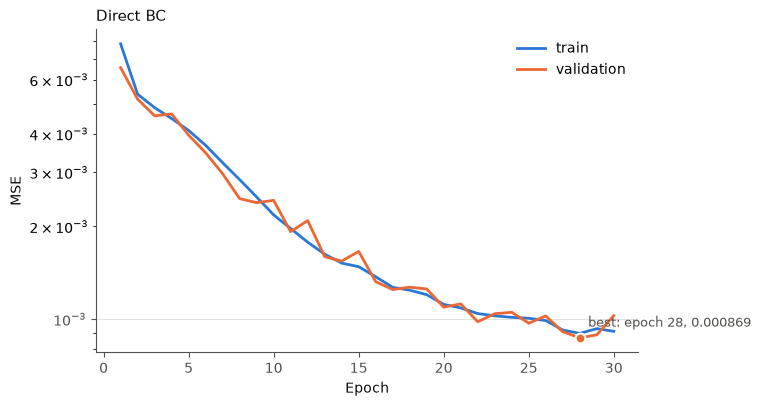

In [13]:
X_train, y_train = to_tensor(normalize(train["obs"], norm)), to_tensor(train["action"])
X_val, y_val = to_tensor(normalize(val["obs"], norm)), to_tensor(val["action"])
bc_model, bc_history = train_regressor(make_mlp(OBS_DIM, 1), X_train, y_train, X_val, y_val, epochs=30, batch_size=256, lr=1e-3, seed=BC_SEED)
plot_training_curves(bc_history, title="Direct BC")

with torch.no_grad():
    val_pred = bc_model(X_val).numpy()
print(f"Val R2: {r2(val_pred, y_val.numpy()):.4f}")
bc_accuracy, bc_per_torque = torque_accuracy(val_pred, y_val.numpy())
print(f"Val accuracy (nearest torque): {bc_accuracy:.4f}")
print(bc_per_torque)

def bc_policy(obs):
    with torch.no_grad():
        action = bc_model(to_tensor(normalize(obs, norm))).numpy()
    return TORQUES[nearest_torque(action)].reshape(action.shape)

display(summary_function(harness_function(bc_policy, "Direct BC", POLICY_EVAL_SEEDS, c)).style.format(precision=3).hide(axis="index"))

This is a clear visualization that the behavioral cloning agent learned well (as expected)! Both the training and validation curves overlap and drop errors as we reach 30 epochs, meaning that it didn't overfit and it learned consistently, and any more epochs likely wouldn't help much.

In [14]:
# Global row indices (into the demos arrays) of every training transition
train_rows = np.flatnonzero(np.isin(demos["episode_id"], split_ids["train"]))
assert max(LABEL_SIZES) <= len(train_rows), "Largest label subset is bigger than the training split."

# One shuffled order of the training rows per seed; D_lab(N) for that seed is its first N entries,
# so the subsets are nested by construction: D_lab(32) is inside D_lab(128), and so on
label_subsets = {s: np.random.default_rng([LABEL_SEED_BASE, s]).permutation(train_rows)[:max(LABEL_SIZES)] for s in LABEL_SEEDS}
for s, subset in label_subsets.items():
    assert np.isin(subset, train_rows).all() and len(np.unique(subset)) == len(subset), f"Seed {s}: subset has non-training rows or duplicates."
with open(LABEL_PATH, "w") as f:
    json.dump({"label_seed_base": LABEL_SEED_BASE, "seeds": LABEL_SEEDS, "sizes": LABEL_SIZES,
               "subsets": {str(s): subset.tolist() for s, subset in label_subsets.items()}}, f)

# $III$. Dynamics Data

We now introduce stage 1 of the LAPO paper which is the joint training of an inverse dynamics model (IDM) and forward dynamics model (FDM). The goal is straightforward: remember that we assume we only have state-only demonstrations and are missing any recorded actions the expert took. Traditional behavior cloning as done in the previous section uses actions to train the model, so we still need the actions to train our LAPO agent. To accomplish this, we need to generate the actions ourselves which we call latent actions $z$. The framework then looks like this:

$\phi_{IDM}(s_t, s_{t+1}) \rightarrow z_t \rightarrow \phi_{FDM}(s_t, z_t) \rightarrow \hat{s}_{t+1}$, and we jointly run gradient descent on the single loss function $\mathcal{L} = ||s_{t+1}-\hat{s}_{t+1}||^2$. So the goal is that the IDM produces a latent action that contains all information about the transition to the next state that $s_t$ can't produce (in this way we are saying that the action is like the residual between states), and then test to make sure that that latent is accurate by having the forward dynamics model take that latent and the state to predict the next state. Notice that our loss function compares to the next state, which we do have from our state-only demonstrations!

Additionally, the pipeline needs an information bottleneck. Perhaps you already saw the problem in the initial formulation, but if $\phi_{FDM}$ is trying to predict $s_{t+1}$ which $\phi_{IDM}$ already has, then $\phi_{IDM}$ will learn to just set $z_t = s_{t+1}$ and they will achieve a loss of 0. But of course we don't want our latent action to be the next state! Thus we implement a bottleneck that will prevent $\phi_{IDM}$ from just encoding directly the next state, of which there are a few ways to go about this that will be discussed soon.

There are a couple of issues that we need to be careful about which this section attempts to address. We introduce some information theory to reveal them:

Let conditional entropy $H(a | s)$ represent the question: "if I know the state, how uncertain is the action?" If the expert is deterministic, then $H(a | s) = 0$. This means that if we know the state, we know exactly which action the expert took and therefore do not need $s_{t+1}$ at all.

Define $I(a;s'|s) = H(a|s)-H(a|s,s') \leq H(a|s)$ as representing the question "how much does seeing the next state tell us about the action beyond what the current state already told us?" That simple inequality tells us exactly the point above: if $H(a|s) = 0$, the action is deterministic from the current state, then $I(a; s'|s)$ must equal $0$ thus there is no information that the next state tells us. Because this is a continuous action environment, it would be more accurate to instead use $Var(a|s)$ to be $H(a|s)$. (Note that this was written before swapping to discrete, so actually $H(a|s)$ is the correct usage here).

What does that mean? It means if the actions are deterministic from the current state, then seeing the next state is useless for learning the action, which since our dynamics models are based on that, means the dynamics models are useless, which means our generated latents are useless, which means our dataset to train our lapo agent becomes useless!!!

This leads us to need a new dataset to train the dynamics models, which we will call $\mathcal{D}_D$. The expert demonstrations $\mathcal{D}_E$ contained too much steady-states which create deterministic transitions, so we need more diversity. This is different from the diverse states we had from the warmups though! The warmups provided diversity in the states visited, but now we need diversity in the actions taken, particularly that we need multiple transitions that are in the same starting state but take different actions, so that $Var(a|s) \neq 0$. We won't be able to get the exact same states because it's a continuous environment, so instead we need to induce a bit of randomness to get some independence between actions and states. The simplest way to accomplish this is to force the expert to not be deterministic, meaning it will have to sample its actions stochastically.

It should be noted that this is an issue only because the expert we had is a deterministic trained rl agent in a toy environment. This issue is less likely to occur in real datasets as humans are not deterministic!

The idea: Let's just get some more data but at each step the action will be $a_t \sim \pi_E(\cdot|s_t)$.

For discrete torques there is a better source of this randomness than added noise. The expert's policy is a probability
distribution over the 15 torques, and so far we have always taken its most likely torque. For $\mathcal{D}_D$ the expert instead
**samples** from that distribution, as described above: it mostly does the same thing, but in states where it is unsure between
torques it picks either one, so there the action can't be predicted from the state and the FDM has to read it from $z_t$.
(Replacing actions with random torques would also do this, but this expert falls within a few dozen steps of random torques, even
small ones, so that data would miss the upright states the expert spends its time in.) The sampling is seeded per episode, failed
episodes would be kept, and $\mathcal{D}_D$ is only ever used without its actions, for stage 1.

In [15]:
# Noisy Collector function
def collect_noisy_demonstrations(seed_list, n_episodes, c, max_warmup_steps, w):
    """Like collect_demonstrations, but the expert samples its torque and failed episodes are kept.
    torch is seeded per episode because the expert's sampling draws from torch's random generator."""
    env = gym.make(ENV_ID, reset_noise_scale=c)
    demonstrations, seeds = [], []
    for seed in seed_list:
        obs, info = env.reset(seed=seed)
        rng = np.random.default_rng([seed, 1])
        k = np.random.default_rng([seed, 2]).integers(0, max_warmup_steps, endpoint=True)
        torch.manual_seed(seed)
        transitions, steps, done = [], 0, False
        while not done:
            if steps < k:
                action = rng.uniform(-w, w, size=ACTION_SPACE.shape)
            else:
                action = np.array([TORQUES[int(expert.predict(obs, deterministic=False)[0])]])
            qpos, qvel = env.unwrapped.data.qpos.copy(), env.unwrapped.data.qvel.copy()
            next_obs, reward, terminated, truncated, info = env.step(action)
            if steps >= k:
                transitions.append((obs, action, next_obs, reward, terminated, truncated, qpos, qvel, steps, k))
            obs, steps, done = next_obs, steps + 1, terminated or truncated
        if transitions:
            demonstrations.append(transitions)
            seeds.append(seed)
        if len(demonstrations) == n_episodes:
            break
    env.close()
    assert len(demonstrations) == n_episodes, f"{n_episodes} were not recovered before exhausting the entire list of {len(seed_list)} seeds."
    return {"Demonstration": demonstrations, "Seed": seeds}

In [16]:
assert not set(DYN_SEEDS) & (set(DEMO_SEEDS) | set(POLICY_EVAL_SEEDS) | set(EXPERT_EVAL_SEEDS)), "Dynamics seeds overlap other seeds."
assert max(DYN_SEEDS + DEMO_SEEDS + POLICY_EVAL_SEEDS + EXPERT_EVAL_SEEDS) < ONLINE_SEED_BASE, "Online seeds overlap other seeds."

# Collect the dataset, or load it if one made the same way is saved
dyn_recipe = {"expert_sha256": EXPERT_SHA256, "reset_noise_scale": float(c), "max_warmup_steps": int(MAX_WARMUP_STEPS),
              "warmup_scale": float(WARMUP_SCALE), "n_episodes": N_DYN_EPISODES, "dyn_seeds": DYN_SEEDS}
saved_meta = {}
if os.path.exists(DYN_PATH) and os.path.exists(DYN_META_PATH):
    with open(DYN_META_PATH) as f:
        saved_meta = json.load(f)
if all(saved_meta.get(key) == value for key, value in dyn_recipe.items()):
    dyn_meta = saved_meta
    print("Loaded the saved dynamics dataset")
else:
    out = collect_noisy_demonstrations(DYN_SEEDS, N_DYN_EPISODES, c, MAX_WARMUP_STEPS, WARMUP_SCALE)
    data = flatten_episodes(out["Demonstration"], out["Seed"])
    np.savez_compressed(DYN_PATH, **data)
    dyn_meta = dict(dyn_recipe, env_id=ENV_ID, expert_path=EXPERT_PATH, n_transitions=int(len(data["obs"])), kept_seeds=[int(s) for s in out["Seed"]])
    with open(DYN_META_PATH, "w") as f:
        json.dump(dyn_meta, f, indent=2)

with np.load(DYN_PATH) as f:
    dynamics = dict(f)
dyn_replay_error = check_dataset(dynamics, dyn_meta, keeps_failures=True)
dyn_differs = np.mean(np.abs(expert_torques(dynamics["obs"]) - dynamics["action"]) > 1e-9)
print(f"{dyn_meta['n_episodes']} episodes ({int(dynamics['truncated'].sum())} reached the time limit, mean length {np.bincount(dynamics['episode_id']).mean():.0f}), "
      f"{dyn_meta['n_transitions']} transitions, replay error {dyn_replay_error:.1e}")
print(f"The sampled torque differs from the expert's most likely torque on {dyn_differs:.1%} of steps")

Loaded the saved dynamics dataset
200 episodes (182 reached the time limit, mean length 957), 191386 transitions, replay error 0.0e+00
The sampled torque differs from the expert's most likely torque on 38.9% of steps


In [17]:
# Expert transitions with the frozen demo normalizer
E_tr, E2_tr = to_tensor(normalize(train["obs"], norm)), to_tensor(normalize(train["next_obs"], norm))
E_va, E2_va = to_tensor(normalize(val["obs"], norm)), to_tensor(normalize(val["next_obs"], norm))

# L1: supervised IDM (s, s') -> a, the ceiling for stage 1 (labels used only to measure)
torch.manual_seed(DIAG_SEED)
supervised_idm, _ = train_regressor(make_mlp(2 * OBS_DIM, 1), torch.cat([E_tr, E2_tr], dim=1), to_tensor(train["action"]),
                                    torch.cat([E_va, E2_va], dim=1), to_tensor(val["action"]), epochs=DIAG_EPOCHS, batch_size=256, lr=1e-3, seed=DIAG_SEED)
with torch.no_grad():
    l1_pred = supervised_idm(torch.cat([E_va, E2_va], dim=1)).numpy()
l1_accuracy, l1_per_torque = torque_accuracy(l1_pred, val["action"])
print(f"L1 accuracy on expert val (nearest torque): {l1_accuracy:.4f}")
print(l1_per_torque)

# The sampled-expert data with the same normalizer, split by episode the same way (no actions are used from here on)
dyn_train, dyn_val, _, _ = train_val_test_split(dynamics, TRAIN_FRACTION, VAL_FRACTION, TEST_FRACTION)
D_tr, D2_tr = to_tensor(normalize(dyn_train["obs"], norm)), to_tensor(normalize(dyn_train["next_obs"], norm))
D_va, D2_va = to_tensor(normalize(dyn_val["obs"], norm)), to_tensor(normalize(dyn_val["next_obs"], norm))

L1 accuracy on expert val (nearest torque): 1.0000
{'-1.000': 1.0, '-0.571': 1.0, '-0.429': 1.0, '-0.143': 1.0, '+0.000': 1.0, '+0.143': 1.0, '+0.429': 1.0, '+1.000': 1.0}


The results: the visibility problem, being able to see the difference in states to figure out the action, is solved. The supervised IDM as a simple model with given action data is able to predict the correct action so that ceiling means the IDM without actions (the first stage of LAPO) can do it too.

# $IV$. Stage 1: Latent Model

We have already introduced the inverse dynamics model and forward dynamics model, but we will briefly review it again here:

IDM: $\phi_{IDM} : (o_t, o_{t+1}) \rightarrow z_t$

FDM: $\phi_{FDM} : (o_t, z_t) \rightarrow \hat{o}_{t+1}$

Now we introduce the third model that exists in this pipeline: Vector Quantization. Recall before that in this simple two model pipeline, the IDM will learn to encode purely $o_{t+1}$ so that the FDM can perfectly predict $\hat{o}_{t+1} = o_{t+1}$ and attain a score of zero. We do not want that or else our latent actions $z_t$ (whose whole purpose is to accurately act as the missing actions from our dataset) will be useless. We combat this by using a information bottleneck to prevent the IDM from encoding any information about the state in its latent action, so that the latent action only carries information that isn't present in the states. In other words, we want a latent $z$ that tells us everything there is to $s_{t+1}$ that is not available from $s$.

Define the quantizer as a codebook which is a list of $K$ vectors $c_k$ with the rule: for any input z (as we will be inputting the IDM's output to the quantizer), output the vector $c_k$ that is closest to z, i.e. minimizing $||z-c_k||^2$. This forces the latent to be 1 of K codes and therefore makes it extremely difficult to encode a 9 dimension state!

IDM first: This mlp will take in the inputs $(o_t, o_{t+1}) \in \mathbb{R}^{2\times8}$ as we have removed one feature from earlier and therefore give two 8-dimensional vectors. It will output a latent vector $z_t \in \mathbb{R}^m$. Despite the action space being 1 in this environment, we don't set $m=1$: following the paper, $m = 64$, which the quantizer splits into $2 \times 4$ pieces of 8 numbers.

Quantizer next: This stores the codebooks, takes in the latent from the IDM and outputs an encoded latent $z_t^{ST}$. Following the paper, each of the 8 pieces is replaced by the nearest of 16 codebook vectors (2 codebooks, each shared by 4 pieces), and the codebooks are updated as moving averages of the pieces assigned to them (EMA) instead of by gradient descent. A small commitment loss pulls the IDM's output toward its codes.

FDM last: Takes in $o_t$ and the quantized latent $z_t^{ST}$ and outputs the predicted change, so $\hat{o}_{t+1} = o_t + \hat{\Delta}_t \in \mathbb{R}^8$ (recall that we are now dealing with observations and not states formally because we dropped a feature so it will no longer be dealing with the entire state)

In [18]:
class VectorQuantizer(nn.Module):
    """The paper's EMA vector quantizer: N_CODEBOOKS codebooks of N_CODES vectors, each shared by N_LATENTS pieces of the latent."""
    def __init__(self):
        super().__init__()
        embedding = torch.empty(N_CODEBOOKS, N_CODES, EMBED_DIM).uniform_(-5 / N_CODES, 5 / N_CODES)
        self.register_buffer("embedding", embedding)
        self.register_buffer("ema_count", torch.zeros(N_CODEBOOKS, N_CODES))
        self.register_buffer("ema_weight", embedding.clone())

    def forward(self, z):
        # Pieces are indexed (codebook, batch, piece, dim); each is replaced by its nearest code
        B = len(z)
        x = z.view(B, N_CODEBOOKS, N_LATENTS, EMBED_DIM).permute(1, 0, 2, 3)
        flat = x.detach().reshape(N_CODEBOOKS, -1, EMBED_DIM)
        dist = flat.square().sum(-1, keepdim=True) + self.embedding.square().sum(-1)[:, None, :] - 2 * torch.bmm(flat, self.embedding.transpose(1, 2))
        idx = dist.argmin(-1)
        zq = torch.gather(self.embedding, 1, idx[..., None].expand(-1, -1, EMBED_DIM)).view_as(x)

        # Move each code toward the average of the pieces assigned to it
        if self.training:
            with torch.no_grad():
                onehot = F.one_hot(idx, N_CODES).float()
                self.ema_count.mul_(EMA_DECAY).add_(onehot.sum(1), alpha=1 - EMA_DECAY)
                self.ema_weight.mul_(EMA_DECAY).add_(torch.bmm(onehot.transpose(1, 2), flat), alpha=1 - EMA_DECAY)
                count = self.ema_count + 1e-5
                count = count / (count.sum(-1, keepdim=True) + N_CODES * 1e-5) * self.ema_count.sum(-1, keepdim=True)
                self.embedding.copy_(self.ema_weight / count[..., None].clamp_min(1e-5))

        # Straight-through gradient; the codes come back indexed (batch, codebook, piece)
        commitment_loss = COMMITMENT * F.mse_loss(x, zq.detach())
        z_st = x + (zq - x).detach()
        codes = idx.view(N_CODEBOOKS, B, N_LATENTS).permute(1, 0, 2)
        return z_st.permute(1, 0, 2, 3).reshape(B, -1), commitment_loss, codes

In [19]:
class Stage1(nn.Module):
    def __init__(self, obs_dim):
        super().__init__()
        self.idm = make_mlp(2 * obs_dim, LATENT_DIM)
        self.vq = VectorQuantizer()
        self.fdm = make_mlp(obs_dim + LATENT_DIM, obs_dim)

    def encode(self, s, s2):
        z = self.idm(torch.cat([s, s2], dim=1))
        z_st, _, codes = self.vq(z)
        return z, z_st, codes

    def forward(self, s, s2):
        z = self.idm(torch.cat([s, s2], dim=1))
        z_st, vq_loss, codes = self.vq(z)
        return self.fdm(torch.cat([s, z_st], dim=1)), vq_loss, codes

@torch.no_grad()
def encode_all(model, S, S2, chunk=8192):
    """Raw latent z, quantized latent z_q and codes for every transition (model in eval mode, so the codebooks stay fixed)."""
    model.eval()
    parts = [model.encode(S[i:i + chunk], S2[i:i + chunk]) for i in range(0, len(S), chunk)]
    return tuple(torch.cat([p[j] for p in parts]) for j in range(3))

@torch.no_grad()
def reconstruction_error(model, S, S2, chunk=8192):
    model.eval()
    total = sum(F.mse_loss(model(S[i:i + chunk], S2[i:i + chunk])[0], S2[i:i + chunk] - S[i:i + chunk], reduction="sum").item()
                for i in range(0, len(S), chunk))
    return total / S.numel()

def codes_in_use(codes):
    """Perplexity (effective number of codes in use) of each codebook, averaged over the codebooks."""
    perplexities = []
    for b in range(N_CODEBOOKS):
        counts = torch.bincount(codes[:, b].flatten(), minlength=N_CODES).float()
        p = counts[counts > 0] / counts.sum()
        perplexities.append(torch.exp(-(p * torch.log(p)).sum()).item())
    return float(np.mean(perplexities))

def train_stage1(S_train, S2_train, S_val, S2_val, seed, steps=STAGE1_STEPS):
    """The paper's recipe: `steps` steps of AdamW on random batches, gradients clipped at 2."""
    torch.manual_seed(seed)
    model = Stage1(S_train.shape[1])
    optimizer = torch.optim.AdamW(model.parameters(), lr=STAGE1_LR)
    history, recent = {"train_loss": [], "val_loss": [], "codes_in_use": []}, []
    for step in range(1, steps + 1):
        model.train()
        rows = torch.randint(len(S_train), (BATCH_SIZE,))
        s, s2 = S_train[rows], S2_train[rows]
        pred_delta, vq_loss, codes = model(s, s2)
        rec_loss = F.mse_loss(pred_delta, s2 - s)
        optimizer.zero_grad()
        (rec_loss + vq_loss).backward()
        nn.utils.clip_grad_norm_(model.parameters(), 2)
        optimizer.step()
        recent.append(rec_loss.item())
        if step % (steps // 20) == 0:
            history["train_loss"].append(float(np.mean(recent)))
            history["val_loss"].append(reconstruction_error(model, S_val, S2_val))
            history["codes_in_use"].append(codes_in_use(encode_all(model, S_val, S2_val)[2]))
            recent = []
    model.eval()
    return model, history

Stage 1 is trained twice with the same settings, once on the expert demos $\mathcal{D}_E$ (the expert taking its most likely
torque) and once on $\mathcal{D}_D$ (the expert sampling), so the table below shows what the sampling does. Both read the actions only to measure. **L2 (raw latent)** predicts the expert's torque from the
IDM's output before the quantizer; **L2 (codes)** predicts it from the quantized latent, which is the only thing the FDM sees, so
it is the real test of whether the bottleneck carries the action. L1 above is the ceiling for both.

demos: loaded the saved stage 1 model
sampled expert: loaded the saved stage 1 model


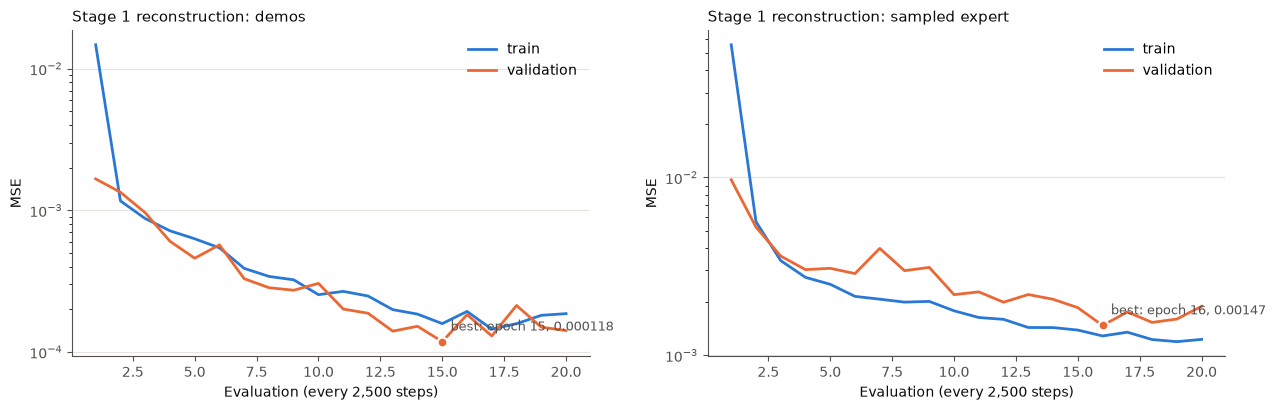

In [20]:
# Train stage 1 on each dataset, or load it if a model trained the same way is saved
norm_sha256 = hashlib.sha256(np.concatenate([norm["keep"], norm["mean"], norm["std"]]).tobytes()).hexdigest()
demo_recipe = {key: metadata[key] for key in ["expert_sha256", "reset_noise_scale", "max_warmup_steps", "warmup_scale", "kept_seeds"]}
stage1_data = {"demos": (E_tr, E2_tr, E_va, E2_va), "sampled expert": (D_tr, D2_tr, D_va, D2_va)}
stage1_models, stage1_histories, stage1_recipes = {}, {}, {}
for name, (S_train, S2_train, S_val, S2_val) in stage1_data.items():
    recipe = {"data": name, "demos": demo_recipe, "dynamics": dyn_recipe if name == "sampled expert" else None,
              "split": [SPLIT_SEED, TRAIN_FRACTION, VAL_FRACTION], "norm_sha256": norm_sha256, "seed": STAGE1_SEED, "steps": STAGE1_STEPS,
              "lr": STAGE1_LR, "batch_size": BATCH_SIZE, "codebooks": N_CODEBOOKS, "latents": N_LATENTS, "embed_dim": EMBED_DIM,
              "codes": N_CODES, "commitment": COMMITMENT, "ema_decay": EMA_DECAY}
    path = STAGE1_PATH.format(name.replace(" ", "_"))
    saved = torch.load(path) if os.path.exists(path) else {}
    if not STAGE1_RETRAIN and saved.get("recipe") == recipe:
        model, history = Stage1(OBS_DIM), saved["history"]
        model.load_state_dict(saved["model"])
        model.eval()
        print(f"{name}: loaded the saved stage 1 model")
    else:
        model, history = train_stage1(S_train, S2_train, S_val, S2_val, STAGE1_SEED)
        torch.save({"recipe": recipe, "model": model.state_dict(), "history": history}, path)
    stage1_models[name], stage1_histories[name], stage1_recipes[name] = model, history, recipe

fig, axes = plt.subplots(1, len(stage1_histories), figsize=(13, 4.2))
for ax, (name, history) in zip(axes, stage1_histories.items()):
    plot_training_curves(history, ax=ax, title=f"Stage 1 reconstruction: {name}")
    ax.set_xlabel(f"Evaluation (every {STAGE1_STEPS // 20:,} steps)", color=INK)
plt.tight_layout()
plt.show()

In [21]:
def probe_accuracy(X_train, y_train, X_val, y_val, n_classes=N_ACTION_BINS):
    """Accuracy on X_val of an MLP classifier for the expert's action trained on X_train (labels used only to measure)."""
    mean, std = X_train.mean(dim=0), X_train.std(dim=0).clamp_min(1e-8)
    Xs_train, Xs_val = (X_train - mean) / std, (X_val - mean) / std
    torch.manual_seed(DIAG_SEED)
    probe = make_mlp(X_train.shape[1], n_classes)
    optimizer = torch.optim.Adam(probe.parameters(), lr=1e-3)
    for epoch in range(DIAG_EPOCHS):
        order = torch.randperm(len(Xs_train))
        for start in range(0, len(Xs_train), 256):
            rows = order[start:start + 256]
            loss = F.cross_entropy(probe(Xs_train[rows]), y_train[rows])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    with torch.no_grad():
        return float((probe(Xs_val).argmax(dim=1).numpy() == y_val).mean())

classes_E_tr, classes_E_va = torch.tensor(nearest_torque(train["action"])), nearest_torque(val["action"])
check_rows = {}
for name, model in stage1_models.items():
    z_tr, zq_tr, _ = encode_all(model, E_tr, E2_tr)
    z_va, zq_va, codes_va = encode_all(model, E_va, E2_va)
    check_rows[name] = {"L2 (raw latent)": probe_accuracy(z_tr, classes_E_tr, z_va, classes_E_va),
                        "L2 (codes)": probe_accuracy(zq_tr, classes_E_tr, zq_va, classes_E_va),
                        f"Codes in use (of {N_CODES})": codes_in_use(codes_va)}
stage1_checks = pd.DataFrame(check_rows).T.rename_axis("Stage 1 trained on")
display(stage1_checks.style.format(precision=3))

stage1 = stage1_models["sampled expert"]
l2_gap = l1_accuracy - stage1_checks.loc["sampled expert", "L2 (codes)"]
print(f"L1 (supervised IDM): {l1_accuracy:.3f}; always guessing the most common torque: {np.bincount(classes_E_va).max() / len(classes_E_va):.3f}")
print(f"L2 (codes) close to L1 for the stage 1 used below: {l2_gap <= MAX_L2_GAP} (accuracy gap {l2_gap:.3f}, allowed {MAX_L2_GAP})")

,L2 (raw latent),L2 (codes),Codes in use (of 16)
Stage 1 trained on,,,
demos,0.999,0.761,9.628
sampled expert,0.997,0.885,9.358


L1 (supervised IDM): 1.000; always guessing the most common torque: 0.312
L2 (codes) close to L1 for the stage 1 used below: False (accuracy gap 0.115, allowed 0.1)


Results: The L2 (codes) is the actually relevant column here, and demos is where the expert always takes the most confident torque bin while sampled experts has a bit more standard exploration to it so the actor isn't always confident. Real human footage, where humans are not always playing the best possible move, is much more similar to the sampled expert, and it shows that not playing perfectly is better for learning.

/Users/orentieyah/Documents/ORFE Senior Thesis/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


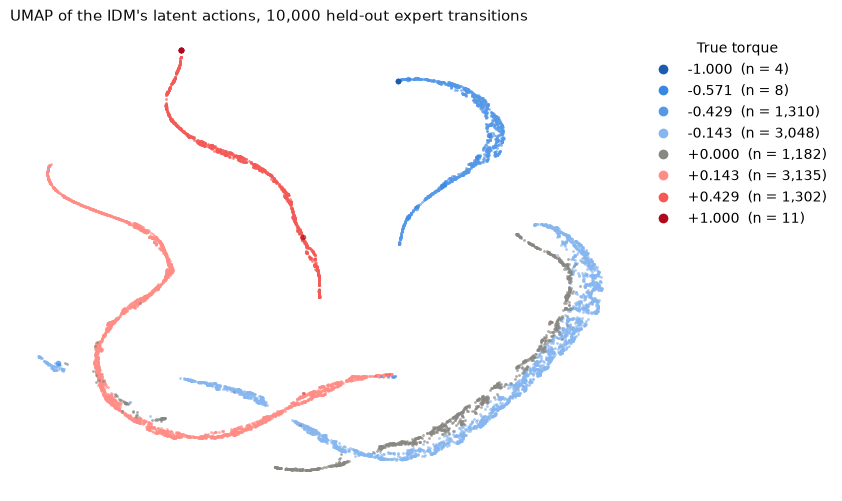

In [29]:
import umap

# The stage 1 used in every later section, on a fixed random sample of held-out expert transitions (the torques only colour the points)
rows = np.random.default_rng(0).choice(len(test["obs"]), size=min(10_000, len(test["obs"])), replace=False)
latents = encode_all(stage1, to_tensor(normalize(test["obs"][rows], norm)), to_tensor(normalize(test["next_obs"][rows], norm)))[0].numpy()
embedding = umap.UMAP(random_state=0, n_jobs=1).fit_transform(latents)
torque_idx = nearest_torque(test["action"][rows])

# Diverging colours: blue for negative torques, red for positive, darker for larger torques, gray for zero
BLUES = ["#86b6ef", "#6da7ec", "#5598e7", "#3987e5", "#2a78d6", "#256abf", "#1c5cab"]
REDS = ["#ff8c85", "#ff6f69", "#f45956", "#e34948", "#d2383a", "#c1252c", "#b0081d"]
def torque_color(i):
    k = i - N_ACTION_BINS // 2
    return "#898781" if k == 0 else (REDS if k > 0 else BLUES)[abs(k) - 1]

fig, ax = plt.subplots(figsize=(8, 6))
used, counts = np.unique(torque_idx, return_counts=True)
for i, n in sorted(zip(used, counts), key=lambda pair: -pair[1]):
    ax.scatter(*embedding[torque_idx == i].T, s=4 if n > len(rows) / 100 else 16, color=torque_color(i), alpha=0.7, linewidths=0, rasterized=True)
ax.legend(handles=[plt.Line2D([], [], marker="o", linestyle="", markersize=6, color=torque_color(i), label=f"{TORQUES[i]:+.3f}  (n = {n:,})")
                   for i, n in zip(used, counts)], title="True torque", frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax.set_xticks([])
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_title(f"UMAP of the IDM's latent actions, {len(rows):,} held-out expert transitions", color=INK, fontsize=11, loc="left")
plt.show()

This is the very aesthetic UMAP graph that the LAPO paper uses. Following the paper's figures 1 and 5: each point is the IDM's continuous (pre-quantization) latent action for one held-out expert transition, squeezed from 64 numbers down to 2 with UMAP, and coloured by the torque the expert actually applied. The torques are used only for the colours.

# $V$. Stage 2: Latent BC

The latent policy sees $o_t$ only and learns to output the latent action the IDM assigned to the expert's transition,
$\pi_\theta(o_t) \approx z_t = \phi_{IDM}(o_t, o_{t+1})$, by MSE on the IDM's raw latent, as in the paper. It is trained on the
expert demos (the behaviour we want to imitate) without their actions; the IDM is frozen.

Loaded the saved latent policy


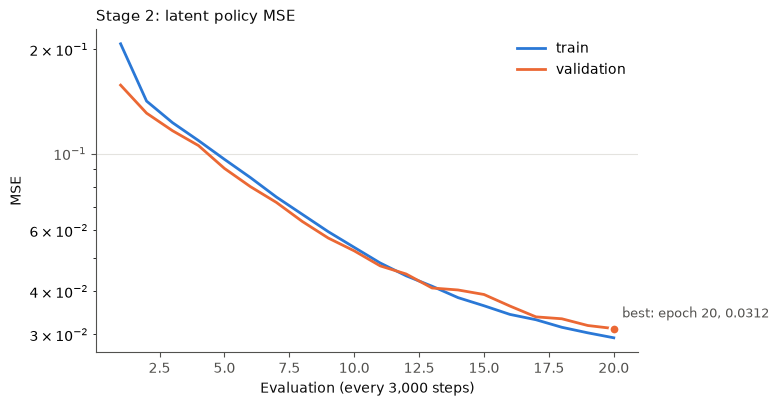

The latent policy explains 91.9% of the latent's variance on expert val (no actions used)


In [22]:
# Targets: the IDM's raw latent for every expert transition (no actions)
Z_tr, Z_va = encode_all(stage1, E_tr, E2_tr)[0], encode_all(stage1, E_va, E2_va)[0]

def train_latent_policy(S_train, Z_train, S_val, Z_val, seed, steps=STAGE2_STEPS):
    """Stage 2: `steps` steps of AdamW on random batches, MSE between pi(o_t) and the IDM's latent."""
    torch.manual_seed(seed)
    model = make_mlp(S_train.shape[1], Z_train.shape[1])
    optimizer = torch.optim.AdamW(model.parameters(), lr=STAGE2_LR)
    history, recent = {"train_loss": [], "val_loss": []}, []
    for step in range(1, steps + 1):
        rows = torch.randint(len(S_train), (BATCH_SIZE,))
        loss = F.mse_loss(model(S_train[rows]), Z_train[rows])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        recent.append(loss.item())
        if step % (steps // 20) == 0:
            with torch.no_grad():
                history["val_loss"].append(F.mse_loss(model(S_val), Z_val).item())
            history["train_loss"].append(float(np.mean(recent)))
            recent = []
    return model.eval(), history

# Train the latent policy, or load it if one trained the same way is saved
stage2_recipe = {"stage1": stage1_recipes["sampled expert"], "seed": STAGE2_SEED, "steps": STAGE2_STEPS, "lr": STAGE2_LR, "batch_size": BATCH_SIZE}
saved = torch.load(STAGE2_PATH) if os.path.exists(STAGE2_PATH) else {}
if not STAGE1_RETRAIN and saved.get("recipe") == stage2_recipe:
    latent_policy, stage2_history = make_mlp(OBS_DIM, LATENT_DIM), saved["history"]
    latent_policy.load_state_dict(saved["model"])
    latent_policy.eval()
    print("Loaded the saved latent policy")
else:
    latent_policy, stage2_history = train_latent_policy(E_tr, Z_tr, E_va, Z_va, STAGE2_SEED)
    torch.save({"recipe": stage2_recipe, "model": latent_policy.state_dict(), "history": stage2_history}, STAGE2_PATH)

ax = plot_training_curves(stage2_history, title="Stage 2: latent policy MSE")
ax.set_xlabel(f"Evaluation (every {STAGE2_STEPS // 20:,} steps)", color=INK)
plt.show()
with torch.no_grad():
    explained = 1 - F.mse_loss(latent_policy(E_va), Z_va).item() / Z_va.var(dim=0).mean().item()
print(f"The latent policy explains {explained:.1%} of the latent's variance on expert val (no actions used)")

Results: The latent policy (LAPO stage 2, a BC trained on the IDM's latents with no actions involved) reaches an $R^2$ of about 0.92 on the held-out validation episodes. That is pretty good given that it predicts all 64 numbers of the IDM's raw latent from the current observation alone, and the part that matters gets through: in section VI its output is decoded to the correct torque 98.4% of the time which is the more practical result.

# $VI$. Stage 3: Offline Decoding

The labels come in only now. For each label budget $N$ in `LABEL_SIZES` and each label seed, the labelled set is the first $N$
rows of that seed's subset from section II. A small decoder maps the frozen latent policy's output to the 15 torques
(cross-entropy, as in the paper), and BC is trained on the **same** $N$ labels from scratch, with the same number of steps, so the
comparison isolates what the action-free data adds. Neither uses a validation set, since that would mean more labels. Both are
scored offline (accuracy on expert test) and in the environment with the harness from section I.

In [23]:
# Every demo row, normalized, its torque index, and the latent policy's output (labels used only where a subset says so)
X_all, y_all = to_tensor(normalize(demos["obs"], norm)), torch.tensor(nearest_torque(demos["action"]))
X_test, y_test = to_tensor(normalize(test["obs"], norm)), nearest_torque(test["action"])
with torch.no_grad():
    PI_all, PI_test = latent_policy(X_all), latent_policy(X_test)

def fit_classifier(X, y, hidden, seed, n_classes=N_ACTION_BINS, label_smoothing=0.0, steps=STAGE3_STEPS):
    """Cross-entropy for `steps` steps on random batches of the labelled rows only."""
    torch.manual_seed(seed)
    model = make_mlp(X.shape[1], n_classes, hidden=hidden)
    optimizer = torch.optim.AdamW(model.parameters(), lr=STAGE3_LR)
    for step in range(steps):
        rows = torch.randint(len(X), (min(BATCH_SIZE, len(X)),))
        loss = F.cross_entropy(model(X[rows]), y[rows], label_smoothing=label_smoothing)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return model.eval()

def torque_policy(net, through_latent_policy):
    """Harness policy: normalize the observation, pick the most likely torque."""
    def policy(obs):
        x = to_tensor(normalize(obs, norm))[None]
        with torch.no_grad():
            logits = net(latent_policy(x)) if through_latent_policy else net(x)
        return np.array([TORQUES[int(logits.argmax())]])
    return policy

stage3_rows, stage3_models = [], {}
for n_labels in LABEL_SIZES:
    for s in LABEL_SEEDS:
        rows = torch.as_tensor(label_subsets[s][:n_labels])
        decoder = fit_classifier(PI_all[rows], y_all[rows], hidden=128, seed=STAGE3_SEED + s, label_smoothing=0.05)
        small_bc = fit_classifier(X_all[rows], y_all[rows], hidden=256, seed=STAGE3_SEED + s)
        stage3_models[(n_labels, s)] = (decoder, small_bc)
        for agent, net, through_latent_policy in [("LAPO", decoder, True), ("Small-label BC", small_bc, False)]:
            with torch.no_grad():
                accuracy = float((net(PI_test if through_latent_policy else X_test).argmax(1).numpy() == y_test).mean())
            episodes = harness_function(torque_policy(net, through_latent_policy), agent, POLICY_EVAL_SEEDS, c)
            stage3_rows.append({"Labels": n_labels, "Label seed": s, "Agent": agent, "Accuracy": accuracy,
                                "Success": episodes["Success"].mean(), "Return": episodes["Return"].mean()})
    print(f"{n_labels} labels done")
stage3_results = pd.DataFrame(stage3_rows)

label_efficiency = stage3_results.groupby(["Labels", "Agent"])[["Accuracy", "Success", "Return"]].agg(["mean", "sem"]).unstack("Agent")
display(label_efficiency.style.format(precision=3))
means = stage3_results.groupby(["Labels", "Agent"])["Return"].mean().unstack("Agent")
print(f"LAPO has the higher mean return at {int((means['LAPO'] > means['Small-label BC']).sum())} of {len(LABEL_SIZES)} label budgets")

32 labels done
128 labels done
512 labels done
2048 labels done
8192 labels done


LAPO has the higher mean return at 2 of 5 label budgets


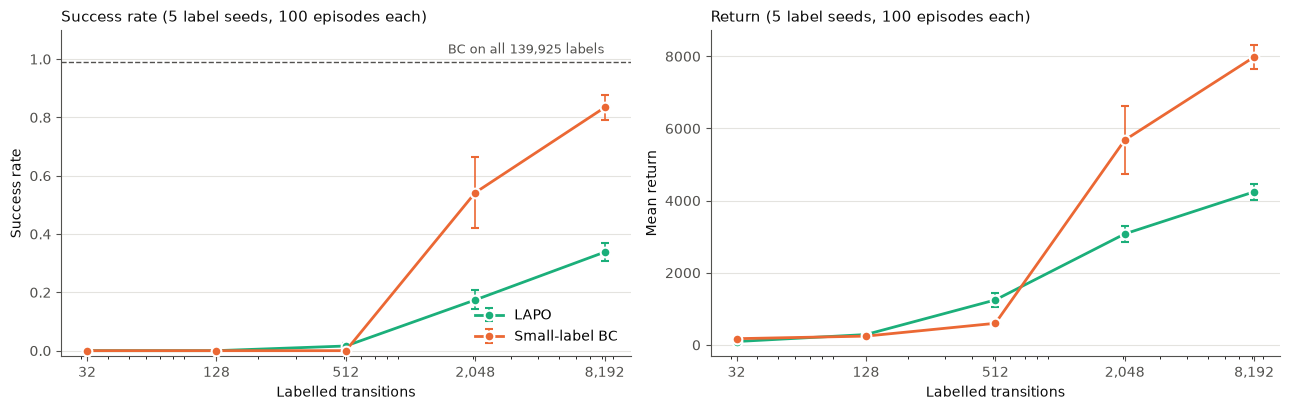

In [24]:
def plot_label_efficiency(results, label_sizes, n_episodes, reference=None, reference_label=None, axes=None):
    """Success rate and return against the number of labels (mean over label seeds, bars = standard error)."""
    if axes is None:
        _, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    n_seeds = results["Label seed"].nunique()
    for ax, metric in zip(axes, ["Success", "Return"]):
        for agent, color in [("LAPO", POLICY_COLORS["LAPO"]), ("Small-label BC", POLICY_COLORS["Direct BC"])]:
            g = results[results["Agent"] == agent].groupby("Labels")[metric]
            ax.errorbar(g.mean().index, g.mean(), yerr=g.sem(), label=agent, color=color, linewidth=2, marker="o", markersize=7,
                        markeredgecolor="white", markeredgewidth=1.5, elinewidth=1.2, capsize=3, zorder=3)
        if metric == "Success":
            if reference is not None:
                ax.axhline(reference, color=MUTED, linestyle="--", linewidth=1, zorder=1)
                ax.annotate(reference_label, (label_sizes[-1], reference), xytext=(0, 4), textcoords="offset points",
                            ha="right", va="bottom", color=MUTED, fontsize=9)
            ax.set_ylim(-0.02, 1.1)
        ax.set_xscale("log")
        ax.set_xticks(label_sizes)
        ax.set_xticklabels([f"{n:,}" for n in label_sizes])
        ax.set_xlabel("Labelled transitions", color=INK)
        ax.set_ylabel("Success rate" if metric == "Success" else "Mean return", color=INK)
        ax.set_title(f"{'Success rate' if metric == 'Success' else 'Return'} ({n_seeds} label seeds, {n_episodes} episodes each)",
                     color=INK, fontsize=11, loc="left")
        style_axes(ax)
    axes[0].legend(frameon=False, loc="lower right")
    return axes

full_bc_success = summary_function(harness_function(bc_policy, "Direct BC", POLICY_EVAL_SEEDS, c))["Success_rate"].item()
plot_label_efficiency(stage3_results, LABEL_SIZES, len(POLICY_EVAL_SEEDS), full_bc_success, f"BC on all {len(train['obs']):,} labels")
plt.tight_layout()
plt.show()

# $VI$ B. Decoding Without Labels

Section VI needed expert labels to translate the latent into torques. Here the agent makes its own: it knows every torque it
presses, so every step it plays is a labelled transition. The decoder is trained on the IDM's latent of those transitions, which
describes what happened whoever played, rather than on the latent policy's output, which predicts the expert's choice. It is learned
in `SELF_PLAY_ROUNDS` rounds of `SELF_PLAY_STEPS` steps: the first round presses uniformly random torques, and each later round plays
with the current decoder (sampling its torques) and retrains on everything so far, so the labels come from the states the agent itself
reaches. Each round is scored like section VI. This is a simpler form of the paper's online decoding (its sections 4.3 and 5), and
section VII then fine-tunes the final decoder online alongside the others.

In [25]:
def own_play(n_steps, seed_base, first_episode, c, decoder=None):
    """n_steps of the agent's own play, recording every transition and the torque it pressed: uniformly random torques without
    a decoder, otherwise torques sampled from the decoder's probabilities for the latent policy's output."""
    env = gym.make(ENV_ID, reset_noise_scale=c)
    data, episode = {"obs": [], "action": [], "next_obs": []}, first_episode
    while len(data["obs"]) < n_steps:
        obs, info = env.reset(seed=seed_base + episode)
        rng = np.random.default_rng([seed_base + episode, 1])
        done = False
        while not done and len(data["obs"]) < n_steps:
            if decoder is None:
                action = int(rng.integers(N_ACTION_BINS))
            else:
                with torch.no_grad():
                    p = torch.softmax(decoder(latent_policy(to_tensor(normalize(obs, norm))[None]))[0], dim=0).numpy().astype(float)
                action = int(rng.choice(N_ACTION_BINS, p=p / p.sum()))
            next_obs, reward, terminated, truncated, info = env.step(np.array([TORQUES[action]]))
            for key, value in zip(data, (obs, action, next_obs)):
                data[key].append(value)
            obs, done = next_obs, terminated or truncated
        episode += 1
    env.close()
    return {key: np.array(value) for key, value in data.items()}, episode

own_data, own_decoder, own_episodes, own_rows = None, None, 0, []
for _ in range(SELF_PLAY_ROUNDS):
    new, own_episodes = own_play(SELF_PLAY_STEPS, SELF_PLAY_SEED_BASE, own_episodes, c, own_decoder)
    own_data = new if own_data is None else {key: np.concatenate([own_data[key], new[key]]) for key in new}
    own_latents = encode_all(stage1, to_tensor(normalize(own_data["obs"], norm)), to_tensor(normalize(own_data["next_obs"], norm)))[0]
    own_decoder = fit_classifier(own_latents, torch.as_tensor(own_data["action"]), hidden=128, seed=STAGE3_SEED, label_smoothing=0.05)
    with torch.no_grad():
        accuracy = float((own_decoder(PI_test).argmax(1).numpy() == y_test).mean())
    episodes = harness_function(torque_policy(own_decoder, True), "LAPO, no labels", POLICY_EVAL_SEEDS, c)
    own_rows.append({"LAPO decoder from": f"{len(own_data['obs']):,} own steps ({own_episodes} episodes)", "Accuracy": accuracy,
                     "Success": episodes["Success"].mean(), "Return": episodes["Return"].mean()})

# Next to section VI's LAPO, whose decoder learned from expert labels
lapo_expert = stage3_results[stage3_results["Agent"] == "LAPO"].groupby("Labels")[["Accuracy", "Success", "Return"]].mean()
expert_rows = [{"LAPO decoder from": f"{n:,} expert labels", **row.to_dict()} for n, row in lapo_expert.iterrows()]
display(pd.DataFrame(own_rows + expert_rows).style.format(precision=3).hide(axis="index"))

LAPO decoder from,Accuracy,Success,Return
512 own steps (84 episodes),0.373,0.000,85.233
"1,024 own steps (134 episodes)",0.421,0.000,136.319
"1,536 own steps (176 episodes)",0.465,0.000,165.498
"2,048 own steps (215 episodes)",0.518,0.000,174.635
"2,560 own steps (252 episodes)",0.547,0.000,302.703
"3,072 own steps (277 episodes)",0.569,0.000,245.653
32 expert labels,0.705,0.000,94.057
128 expert labels,0.932,0.000,287.490
512 expert labels,0.970,0.016,1247.505
"2,048 expert labels",0.981,0.174,3077.402


# $VII$. Online Fine-Tuning

Claim 2: starting from the demonstrations should reach success with far fewer environment steps than PPO from scratch. All four
agents use the same on-policy PPO (one update per episode), the same reset seeds and the same budget of `ONLINE_STEPS` environment
steps; the comparison is in steps rather than episodes because the agents' episodes have very different lengths. **LAPO** and
**BC** start from their section VI policies at `ONLINE_LABEL_SIZE` labels (label seed 0) and **LAPO, no labels** from
its section VI B decoder, each kept frozen as a prior whose logits are
sharpened and added to a trainable residual that starts at zero, so each starts exactly at its offline policy. LAPO without labels already spent `SELF_PLAY_ROUNDS * SELF_PLAY_STEPS` steps of
its budget on its own play, so its run starts at that many steps. **PPO** starts from random weights.

In [26]:
PPO_EPOCHS = 10
PPO_MINIBATCH = 256
PPO_LR = 3e-4
PPO_CLIP = 0.2
PPO_GAMMA = 0.99
PPO_GAE_LAMBDA = 0.95
PPO_ENTROPY = 1e-3

class OnlineActorCritic(nn.Module):
    def __init__(self, prior, obs_dim, n_actions):
        super().__init__()
        self.prior, self.residual, self.critic = prior, make_mlp(obs_dim, n_actions), make_mlp(obs_dim, 1)
        if prior is not None:
            for p in self.prior.parameters():
                p.requires_grad = False
            nn.init.zeros_(self.residual[-1].weight)
            nn.init.zeros_(self.residual[-1].bias)

    def forward(self, x):
        # Sharpen the supervised prior: a tiny per-step sampling error is fatal over a long episode
        logits = self.residual(x) if self.prior is None else 5.0 * self.prior(x) + self.residual(x)
        return logits, self.critic(x).squeeze(-1)

def online_ppo(name, prior, make_env, preprocess, obs_dim, n_actions, total_steps, seed, verbose=True, start_steps=0):
    """On-policy PPO with one update per episode, until total_steps environment steps have been taken (start_steps of them already before)."""
    torch.manual_seed(seed)
    np.random.seed(seed)
    model = OnlineActorCritic(prior, obs_dim, n_actions)
    optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=PPO_LR)
    env = make_env()
    records, steps_done, episode, next_report = [], start_steps, 0, total_steps // 10
    while steps_done < total_steps:
        obs, info = env.reset(seed=ONLINE_SEED_BASE + episode)
        rollout, done = [], False
        while not done:
            x = preprocess(obs)
            with torch.no_grad():
                logits, value = model(x)
                dist = torch.distributions.Categorical(logits=logits)
                action = dist.sample()
            obs, reward, terminated, truncated, info = env.step(int(action.item()))
            done = terminated or truncated
            rollout.append((x[0], action, dist.log_prob(action), float(reward), float(value.item())))
        states, actions, old_logp, rewards, values = zip(*rollout)
        states, actions, old_logp = torch.stack(states), torch.cat(actions), torch.cat(old_logp)

        # GAE with zero bootstrap: every rollout ends at termination or the time limit
        adv = np.zeros(len(rewards), np.float32)
        last, next_value = 0.0, 0.0
        for t in reversed(range(len(rewards))):
            delta = rewards[t] + PPO_GAMMA * next_value - values[t]
            last = delta + PPO_GAMMA * PPO_GAE_LAMBDA * last
            adv[t], next_value = last, values[t]
        returns = torch.tensor(adv + np.asarray(values, np.float32))
        advantages = torch.tensor(adv)
        advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8) if len(adv) > 1 else advantages

        for _ in range(PPO_EPOCHS):
            order = torch.randperm(len(states))
            for start in range(0, len(states), PPO_MINIBATCH):
                ix = order[start:start + PPO_MINIBATCH]
                logits, value_pred = model(states[ix])
                dist = torch.distributions.Categorical(logits=logits)
                ratio = (dist.log_prob(actions[ix]) - old_logp[ix]).exp()
                policy_loss = torch.maximum(-advantages[ix] * ratio, -advantages[ix] * ratio.clamp(1 - PPO_CLIP, 1 + PPO_CLIP)).mean()
                value_loss = 0.5 * F.mse_loss(value_pred, returns[ix])
                loss = policy_loss + 0.5 * value_loss - PPO_ENTROPY * dist.entropy().mean()
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 0.5)
                optimizer.step()

        steps_done += len(rewards)
        records.append({"Agent": name, "Episode": episode, "Steps": steps_done, "Return": sum(rewards), "Length": len(rewards)})
        episode += 1
        if verbose and steps_done >= next_report:
            recent = [r["Return"] for r in records if r["Steps"] > steps_done - total_steps // 10]
            print(f"{name}: {steps_done:,} steps ({episode} episodes), mean return over the last {total_steps // 10:,} steps {np.mean(recent):.1f}")
            next_report += total_steps // 10
    env.close()
    return pd.DataFrame(records)

class LAPOLogits(nn.Module):
    def __init__(self, latent_policy, decoder):
        super().__init__()
        self.latent_policy, self.decoder = copy.deepcopy(latent_policy), copy.deepcopy(decoder)
    def forward(self, x):
        return self.decoder(self.latent_policy(x))

def final_returns(results, total_steps):
    """Return of the episodes that ended in the last tenth of the step budget."""
    last = results[results["Steps"] > 0.9 * total_steps]
    return last.groupby("Agent", sort=False)["Return"].agg(["mean", "median", "count"]).rename(columns={"count": "episodes"})

online_decoder, online_bc = stage3_models[(ONLINE_LABEL_SIZE, LABEL_SEEDS[0])]
idp_preprocess = lambda obs: to_tensor(normalize(obs, norm))[None]
agents = [("LAPO", LAPOLogits(latent_policy, online_decoder), 0), ("LAPO, no labels", LAPOLogits(latent_policy, own_decoder), SELF_PLAY_ROUNDS * SELF_PLAY_STEPS),
          ("BC", copy.deepcopy(online_bc), 0), ("PPO", None, 0)]
online_results = pd.concat([online_ppo(name, prior, make_discrete_env, idp_preprocess, OBS_DIM, N_ACTION_BINS, ONLINE_STEPS, ONLINE_SEED, start_steps=used)
                            for name, prior, used in agents], ignore_index=True)
display(final_returns(online_results, ONLINE_STEPS).style.format(precision=1))

LAPO: 30,045 steps (224 episodes), mean return over the last 30,000 steps 1248.9
LAPO: 60,508 steps (495 episodes), mean return over the last 30,000 steps 1073.3
LAPO: 90,830 steps (636 episodes), mean return over the last 30,000 steps 2000.7
LAPO: 120,345 steps (844 episodes), mean return over the last 30,000 steps 1354.6
LAPO: 150,641 steps (1006 episodes), mean return over the last 30,000 steps 1767.3
LAPO: 180,048 steps (1117 episodes), mean return over the last 30,000 steps 2504.5
LAPO: 210,677 steps (1189 episodes), mean return over the last 30,000 steps 4041.1
LAPO: 240,593 steps (1233 episodes), mean return over the last 30,000 steps 6372.1
LAPO: 270,830 steps (1279 episodes), mean return over the last 30,000 steps 6272.1
LAPO: 300,097 steps (1324 episodes), mean return over the last 30,000 steps 6150.2
LAPO, no labels: 30,023 steps (397 episodes), mean return over the last 30,000 steps 622.9
LAPO, no labels: 60,642 steps (495 episodes), mean return over the last 30,000 steps 2

,mean,median,episodes
Agent,,,
LAPO,6150.2,9355.2,46
"LAPO, no labels",7203.5,9351.6,40
BC,917.3,665.8,304
PPO,2962.4,966.5,96


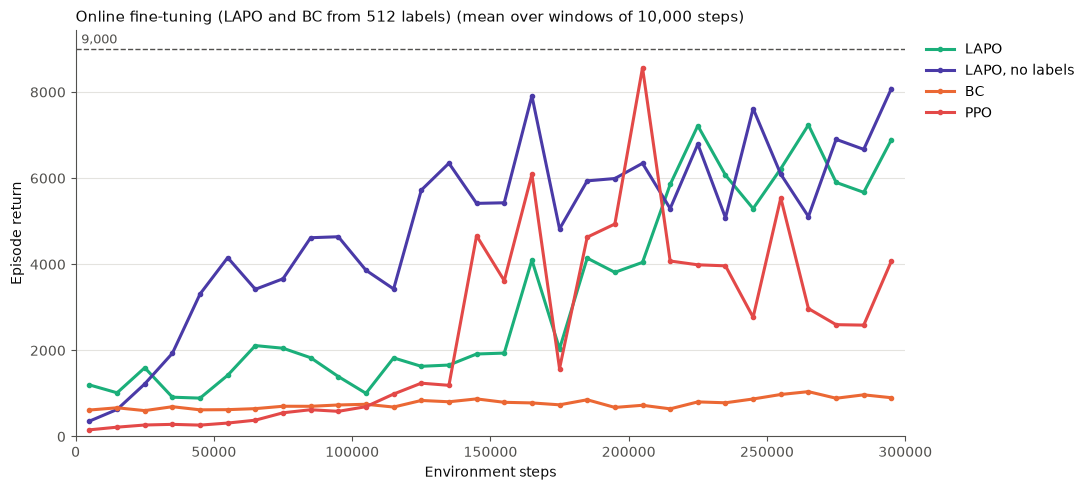

In [27]:
def plot_online(results, total_steps, title, threshold, ax=None, n_windows=30):
    """Mean return of the episodes ending in each of n_windows equal windows of environment steps, one line per agent."""
    if ax is None:
        _, ax = plt.subplots(figsize=(11, 5))
    colors = {"LAPO": POLICY_COLORS["LAPO"], "LAPO, no labels": EXTRA_COLORS[3], "BC": POLICY_COLORS["Direct BC"], "PPO": EXTRA_COLORS[4]}
    edges = np.linspace(0, total_steps, n_windows + 1)
    centers = (edges[:-1] + edges[1:]) / 2
    for name, g in results.groupby("Agent", sort=False):
        means = g.groupby(np.minimum(np.digitize(g["Steps"], edges[1:-1]), n_windows - 1))["Return"].mean()
        ax.plot(centers[means.index], means.values, label=name, color=colors[name], linewidth=2.2, marker="o", markersize=3)
    ax.axhline(threshold, color=MUTED, linestyle="--", linewidth=1)
    ax.annotate(f"{threshold:,}", (0, threshold), xytext=(4, 4), textcoords="offset points", color=MUTED, fontsize=9)
    ax.set_xlim(0, total_steps)
    ax.set_ylim(bottom=0)
    ax.set_xlabel("Environment steps", color=INK)
    ax.set_ylabel("Episode return", color=INK)
    ax.set_title(f"{title} (mean over windows of {total_steps // n_windows:,} steps)", color=INK, fontsize=11, loc="left")
    style_axes(ax)
    ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1.0))
    return ax

plot_online(online_results, ONLINE_STEPS, f"Online fine-tuning (LAPO and BC from {ONLINE_LABEL_SIZE} labels)", EXPERT_SUCCESS_THRESHOLD)
plt.tight_layout()
plt.show()

CONCLUSION: LAPO clearly outperformed both behavioral cloning (which could not fine-tune well online) with both decoding options. Granted, BC would perform far better than LAPO as we would normally expect but only if it has $N \rightarrow \infty$ demonstrations, but on a small amount (512) LAPO performs better which is great. We do not normally assume an infinite amount of good footage, not because there isn't an abundance of footage available, but rather because of the constraints and costs associated with using such footage, so this is a great result overall!

# $VIII$. BONUS: CartPole

As an added bonus section, we examine the pipeline on the much simpler and more well-known environment of cartpole, which is a single pendulum. This is the same pipeline above on `CartPole-v1`, condensed into one cell and reusing the functions above: a PPO expert, demonstrations
(most likely action) and a sampled-expert dataset, stage 1 on the sampled expert with the L1/L2 check, stage 2 on the demos,
decoder vs small-label BC on the same labels, and online fine-tuning on equal step budgets. CartPole has two discrete actions and
fails only when the pole tilts past 12°, so it is far more forgiving than the double pendulum; budgets are smaller to match.

Expert: return 499.4, success 98%; sampling picks another action than its most likely one on 21.8% of steps
Stage 1: L1 1.000, L2 (codes) 1.000


,mean,median,episodes
Agent,,,
LAPO,300.5,496.0,17
BC,500.0,500.0,11
PPO,86.3,36.0,64


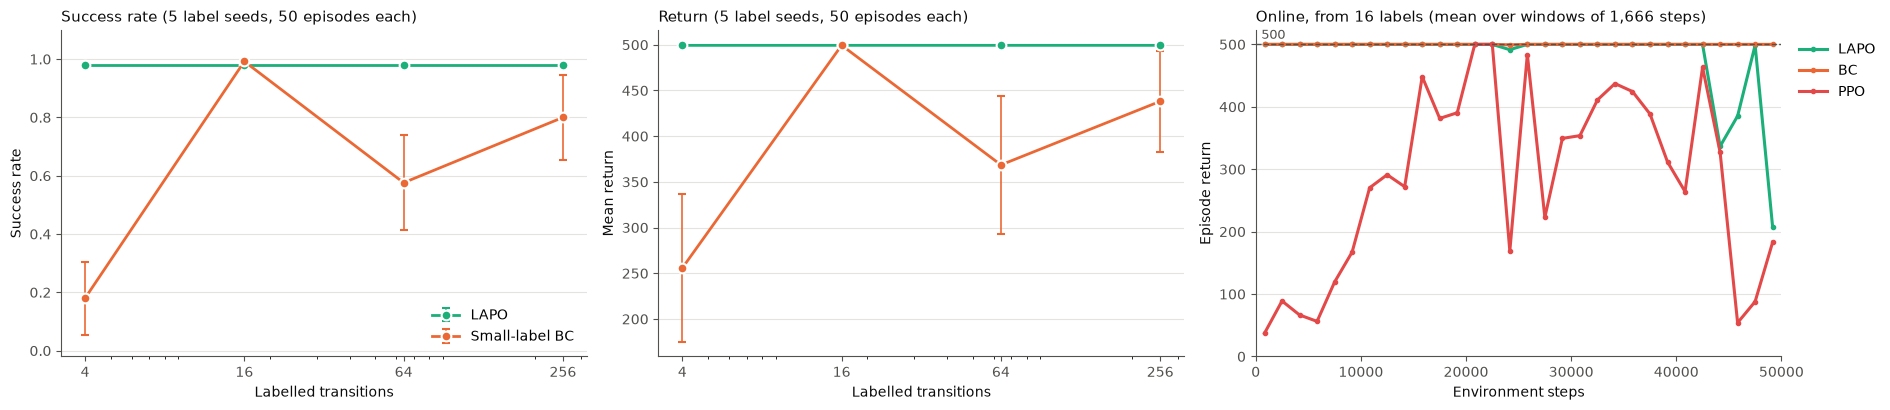

In [28]:
CP_ENV_ID = "CartPole-v1"
CP_EXPERT_PATH = "models/ppo_expert_cartpole"
CP_EXPERT_STEPS = 100_000
CP_N_EPISODES = 100
CP_DEMO_SEEDS = list(range(600_000, 600_000 + CP_N_EPISODES))
CP_SAMPLED_SEEDS = list(range(650_000, 650_000 + CP_N_EPISODES))
CP_EVAL_SEEDS = list(range(700_000, 700_050))
CP_LABEL_SIZES = [4, 16, 64, 256]
CP_STAGE1_STEPS, CP_STAGE2_STEPS, CP_STAGE3_STEPS = 20_000, 20_000, 2_000
CP_ONLINE_LABEL_SIZE = 16
CP_ONLINE_STEPS = 50_000

# Expert: trained once, then loaded
if not os.path.exists(f"{CP_EXPERT_PATH}/best_model.zip"):
    vec_env = make_vec_env(CP_ENV_ID, n_envs=4, seed=EXPERT_SEED)
    eval_env = make_vec_env(CP_ENV_ID, n_envs=1, seed=EXPERT_SEED + 1_000)
    callback = EvalCallback(eval_env, best_model_save_path=CP_EXPERT_PATH, eval_freq=5_000 // 4, n_eval_episodes=10,
                            deterministic=True, verbose=0)
    PPO("MlpPolicy", vec_env, seed=EXPERT_SEED, verbose=0).learn(total_timesteps=CP_EXPERT_STEPS, callback=callback)
    vec_env.close()
    eval_env.close()
cp_expert = PPO.load(f"{CP_EXPERT_PATH}/best_model")

def cp_evaluate(policy, seeds=CP_EVAL_SEEDS):
    """Mean return and success rate (all 500 steps) of policy: obs -> action, one episode per seed."""
    env = gym.make(CP_ENV_ID)
    returns = []
    for seed in seeds:
        obs, info = env.reset(seed=seed)
        total, done = 0.0, False
        while not done:
            obs, reward, terminated, truncated, info = env.step(policy(obs))
            total += reward
            done = terminated or truncated
        returns.append(total)
    env.close()
    return float(np.mean(returns)), float(np.mean(np.array(returns) >= 500))

def cp_collect(seeds, deterministic):
    """One expert episode per seed: its most likely action (deterministic) or a sample from its policy."""
    env = gym.make(CP_ENV_ID)
    data = {"obs": [], "action": [], "next_obs": [], "episode_id": []}
    for e, seed in enumerate(seeds):
        obs, info = env.reset(seed=seed)
        torch.manual_seed(seed)
        done = False
        while not done:
            action = int(cp_expert.predict(obs, deterministic=deterministic)[0])
            next_obs, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated
            for key, value in zip(data, (obs, action, next_obs, e)):
                data[key].append(value)
            obs = next_obs
    env.close()
    return {key: np.array(value) for key, value in data.items()}

cp_expert_return, cp_expert_success = cp_evaluate(lambda obs: int(cp_expert.predict(obs, deterministic=True)[0]))
cp_demos, cp_sampled = cp_collect(CP_DEMO_SEEDS, deterministic=True), cp_collect(CP_SAMPLED_SEEDS, deterministic=False)
cp_differs = float(np.mean(cp_expert.predict(cp_sampled["obs"], deterministic=True)[0] != cp_sampled["action"]))

# Splits by episode, and a normalizer fit on the demos' training split
cp_train, cp_val, cp_test, _ = train_val_test_split(cp_demos, TRAIN_FRACTION, VAL_FRACTION, TEST_FRACTION)
cp_dyn_train, cp_dyn_val, _, _ = train_val_test_split(cp_sampled, TRAIN_FRACTION, VAL_FRACTION, TEST_FRACTION)
cp_mean, cp_std = cp_train["obs"].mean(axis=0), cp_train["obs"].std(axis=0) + 1e-8
cp_t = lambda x: to_tensor((x - cp_mean) / cp_std)
C_tr, C2_tr, C_va, C2_va, C_te = (cp_t(cp_train["obs"]), cp_t(cp_train["next_obs"]), cp_t(cp_val["obs"]),
                                  cp_t(cp_val["next_obs"]), cp_t(cp_test["obs"]))
cy_tr, cy_va, cy_te = torch.tensor(cp_train["action"]), cp_val["action"], cp_test["action"]

# Stage 1 on the sampled expert; L1 from (o_t, o_t+1) and L2 from the codes (labels used only to measure)
cp_stage1, _ = train_stage1(cp_t(cp_dyn_train["obs"]), cp_t(cp_dyn_train["next_obs"]), cp_t(cp_dyn_val["obs"]),
                            cp_t(cp_dyn_val["next_obs"]), STAGE1_SEED, steps=CP_STAGE1_STEPS)
cp_l1 = probe_accuracy(torch.cat([C_tr, C2_tr], dim=1), cy_tr, torch.cat([C_va, C2_va], dim=1), cy_va, n_classes=2)
cz_tr, czq_tr, _ = encode_all(cp_stage1, C_tr, C2_tr)
cz_va, czq_va, _ = encode_all(cp_stage1, C_va, C2_va)
cp_l2 = probe_accuracy(czq_tr, cy_tr, czq_va, cy_va, n_classes=2)

# Stage 2 on the demos, without their actions
cp_latent_policy, _ = train_latent_policy(C_tr, cz_tr, C_va, cz_va, STAGE2_SEED, steps=CP_STAGE2_STEPS)
with torch.no_grad():
    CPI_tr, CPI_te = cp_latent_policy(C_tr), cp_latent_policy(C_te)

# Stage 3: decoder vs BC on the same labels, for each budget and label seed
cp_rows, cp_models = [], {}
for s in LABEL_SEEDS:
    order = np.random.default_rng([LABEL_SEED_BASE, s]).permutation(len(C_tr))
    for n_labels in CP_LABEL_SIZES:
        rows = torch.as_tensor(order[:n_labels])
        decoder = fit_classifier(CPI_tr[rows], cy_tr[rows], hidden=128, seed=STAGE3_SEED + s, n_classes=2,
                                 label_smoothing=0.05, steps=CP_STAGE3_STEPS)
        small_bc = fit_classifier(C_tr[rows], cy_tr[rows], hidden=256, seed=STAGE3_SEED + s, n_classes=2, steps=CP_STAGE3_STEPS)
        cp_models[(n_labels, s)] = (decoder, small_bc)
        for agent, net, through_latent_policy in [("LAPO", decoder, True), ("Small-label BC", small_bc, False)]:
            with torch.no_grad():
                accuracy = float((net(CPI_te if through_latent_policy else C_te).argmax(dim=1).numpy() == cy_te).mean())
                features = cp_latent_policy if through_latent_policy else nn.Identity()
                mean_return, success = cp_evaluate(lambda obs, net=net, features=features: int(net(features(cp_t(obs)[None])).argmax()))
            cp_rows.append({"Labels": n_labels, "Label seed": s, "Agent": agent, "Accuracy": accuracy, "Success": success,
                            "Return": mean_return})
cp_results = pd.DataFrame(cp_rows)

# Online fine-tuning from CP_ONLINE_LABEL_SIZE labels: same PPO, same step budget
cp_decoder, cp_bc = cp_models[(CP_ONLINE_LABEL_SIZE, LABEL_SEEDS[0])]
cp_online = pd.concat([online_ppo(name, prior, lambda: gym.make(CP_ENV_ID), lambda obs: cp_t(obs)[None], 4, 2, CP_ONLINE_STEPS,
                                  ONLINE_SEED, verbose=False)
                       for name, prior in [("LAPO", LAPOLogits(cp_latent_policy, cp_decoder)), ("BC", copy.deepcopy(cp_bc)),
                                           ("PPO", None)]], ignore_index=True)

# Results
print(f"Expert: return {cp_expert_return:.1f}, success {cp_expert_success:.0%}; "
      f"sampling picks another action than its most likely one on {cp_differs:.1%} of steps")
print(f"Stage 1: L1 {cp_l1:.3f}, L2 (codes) {cp_l2:.3f}")
display(cp_results.groupby(["Labels", "Agent"])[["Accuracy", "Success", "Return"]].mean().unstack("Agent").style.format(precision=3))
display(final_returns(cp_online, CP_ONLINE_STEPS).style.format(precision=1))
fig, axes = plt.subplots(1, 3, figsize=(19, 4.2))
plot_label_efficiency(cp_results, CP_LABEL_SIZES, len(CP_EVAL_SEEDS), axes=axes[:2])
plot_online(cp_online, CP_ONLINE_STEPS, f"Online, from {CP_ONLINE_LABEL_SIZE} labels", 500, ax=axes[2])
plt.tight_layout()
plt.show()